# AKE Lab 5 · Zeitreihen: Day-ahead-Lastprognose — Lösung

**Angewandte KI & KI-Engineering · Block B – Spezialisierte Anwendungsgebiete · Woche 5**
Bezug: Foliensatz *Zeitreihen & Reinforcement Learning*, Abschnitte 1–5 · Lektüre: FPP3 (Hyndman & Athanasopoulos) Kap. 1–3, 5, 8, 9

> **Dieses Notebook ist das komplette Lab – es gibt kein separates Aufgabenblatt.** Jede Aufgabe enthält die Aufgabenstellung,
> die Formeln, die Erwartungswerte und die Leitfragen. Der Code ist ausführlich kommentiert: Lesen Sie die Kommentare
> (Zeilen, die mit `#` beginnen) – sie erklären Zeile für Zeile, was passiert.

**Die Aufgabe:** Ein Übertragungsnetzbetreiber muss jeden Tag die Netzlast des Folgetags Stunde für Stunde vorhersagen
(*Day-ahead*). Sie arbeiten mit echten Daten der Regelzone **Amprion** (Westdeutschland, Stundenwerte 2018 bis Juni 2020, Open
Power System Data). Als Messlatte dient die Day-ahead-Prognose des Netzbetreibers selbst, die im Datensatz mitgeliefert wird.

Sie gehen den Weg aus der Vorlesung: Daten verstehen (A1) → Baselines und Backtest (A2) → statistische Modelle (A3) →
LightGBM und LSTM (A4) → Temporal Fusion Transformer und Modellwahl (A5) → Drift und Anomalien im Corona-Lockdown 2020 (A6).

**Charakter:** Übung in **Blöcken während der Vorlesung** – jeder Block folgt direkt auf den Vorlesungsabschnitt, den er vertieft.
**Ihre Zeit ≈ 80 Min.** in der Sitzung, davon **≈ 3–4 Min. reine Rechenzeit** auf der Referenz (4 Kerne / 8 GB, keine GPU).
Den TFT trainieren Sie nicht – er liegt fertig trainiert in `data/models/tft_amprion/`.

> **🎓 Für den Dozenten:** Zeilen mit `# 🎓` sind Vorführ-Notizen: Der Kasten am Zellenanfang sagt, was die Zelle insgesamt tut; die eingestreuten `# 🎓`-Zeilen erklären einzelne Schritte, vor allem Array- und Zeitschnitte. Sie stehen nur in der Lösung, nicht im Starter.

## Organisatorisches

| | |
|---|---|
| **Termin** | Woche 5 (KW 45, 05.11.2026), in sechs Blöcken während der Vorlesung; Besprechung jeweils direkt nach der Arbeitsphase am Beamer |
| **Bezug** | Foliensatz *Zeitreihen & Reinforcement Learning*, Abschn. 1 (Zeitreihen verstehen), 2 (Prognosen bewerten), 3 (ETS, ARIMA, MSTL), 4 (LightGBM, LSTM, TFT), 5 (Anomalien und Drift) |
| **Material** | Ordner `lab05/` im Kursrepository: dieses Notebook, `results_referenz/` (Referenzlogs und TFT-Vorhersagen als Fallback), `lab05_rl_optional.ipynb` (DQN auf CartPole, Vertiefung zu Hause); die Musterlösung folgt nach der Sitzung |
| **Umgebung** | Kursumgebung aktualisieren: `git pull`, danach **`uv sync`** – neu sind `pytorch-forecasting` 1.8.0, `lightning` 2.6.6 und `gymnasium`. Kein Download während des Labs nötig. |
| **Daten** | `data/opsd/amprion_load_2018_2020H1.csv`: 21 888 Stundenwerte (1.1.2018–30.6.2020, UTC), Spalten `load_mw` (Ist-Last), `load_forecast_tso_mw` (Day-ahead-Prognose des Netzbetreibers), `solar_mw`, `wind_mw`; `data/models/tft_amprion/` (TFT-Checkpoint, 1 MB) |

**Fahrplan**

| Aufgabe | Block in der Vorlesung (nach Folie …) | Inhalt | Ihre Zeit | Rechenzeit |
|---|---|---|---|---|
| 0 · Setup | vorab, spätestens zu Beginn | Setup-Zelle, Prüfungen | 2 Min. | Sekunden |
| 1 · Daten erkunden | „Zwischenstand: Zeitreihen verstehen“ | Zeitskalen, Autokorrelation (`CODE`), MSTL-Zerlegung | 15 Min. | Sekunden |
| 2 · Baselines und Backtest | „Die Messlatte“ | Fehlermaße (`CODE`), Baselines (`CODE`), Backtest-Gerüst | 15 Min. | Sekunden |
| 3 · ETS, SARIMA, MSTL | „Zwischenstand: Klassische Modelle“ | Automatik prüfen (`CODE`), SARIMA, MSTL (`CODE`) | 15 Min. | ≈ 1 Min. |
| 4 · LightGBM und LSTM | „Ein LSTM für 24 Stunden“ | Merkmale (`CODE`), LightGBM (`CODE`), LSTM | 15 Min. | ≈ 15 s |
| 5 · TFT und Modellwahl | „Zwischenstand: ML und Deep Learning“ | TFT befragen, Band prüfen (`CODE`), Empfehlung, Endtest | 10 Min. | ≈ 10 s |
| 6 · Drift und Anomalien | „Zwischenstand: Anomalien und Drift“ | Residuen 2020 (`CODE`), Isolation Forest (`CODE`) | 10 Min. | Sekunden |

**Kennzeichnung der Arbeitsarten** (steht am Anfang jeder Teilaufgabe):

| Marke | Was Sie tun |
|---|---|
| `CODE` | eine Lücke selbst füllen (Zeile mit `raise NotImplementedError` durch Ihre Lösung ersetzen) |
| `LIVE` | wird in der Vorlesung gemeinsam geschrieben bzw. vorgeführt – ausführen und mitlesen |
| `AUSFÜHREN` | nur ausführen und die Ausgabe lesen |
| `DENKEN` | Interpretationsfrage in der Markdown-Zelle beantworten |

Wer bei einer Lücke nicht weiterkommt, übernimmt die Zeile aus der Lösung am Beamer – die Aufgaben bauen aufeinander auf.

**Abgabe:** keine. Bringen Sie zur nächsten Sitzung Ihre Vergleichstabelle aus 5.3 und Ihre dreisätzige Modellempfehlung mit.
Für Capstone-Themen mit Zeitreihen (1, 4, 6) ist dieses Notebook eine gute Vorlage: Backtest-Gerüst, Baselines, Merkmale.

## Lernziele

Nach dem Lab können Sie … (Lernziel-Matrix, Woche 5)

- **Erinnern:** die Verfahren naiv, saisonal naiv, ETS, SARIMA, MSTL, LightGBM, LSTM und TFT benennen und einordnen.
- **Verstehen:** erklären, was Trend, Saison, Autokorrelation und ein Backtest mit rollierendem Ursprung sind.
- **Anwenden:** ein Forecasting-Modell leckagefrei trainieren und im Backtest bewerten (MAE, RMSE, MAPE, MASE).
- **Analysieren:** Saisonalität mit ACF und Zerlegung sowie Drift und Anomalien im Residuum analysieren.
- **Bewerten:** eine Modellauswahl begründen – mit Genauigkeit, Aufwand, Unsicherheit und Erklärbarkeit.

## Spielregeln und Hinweise

- **Die Zukunft darf nie ins Training sickern.** Ursprung jeder Prognose ist 23:00 Uhr (UTC) des Vortags; vorhergesagt werden die
  24 Stunden des Folgetags. Jedes Merkmal muss zu diesem Zeitpunkt bekannt sein – also **kein Lag kürzer als 24 h**.
- **Ein Backtest für alle:** 28 Ursprünge vom 7.10. bis 3.11.2019. Alle Modelle werden auf genau diesen 672 Stunden verglichen.
- **Training bis 30.9.2019.** Der **Endtest** (Dezember 2019) wird in Aufgabe 5 **genau einmal** gerechnet – für das Modell, das
  Sie vorher auf dem Backtest ausgewählt haben. Die Daten ab Januar 2020 dienen nur der Drift-Analyse in Aufgabe 6.
- **Kalender in Ortszeit:** Lastprofile folgen der Uhr. Die Hilfsfunktion `kalender()` rechnet UTC in Europe/Berlin um.
- **Reproduzierbarkeit:** feste Zufallszahlen (`seed 0`); jedes Experiment schreibt ein JSON-Log nach `results/`.
- **Fallback:** Läuft der TFT in Aufgabe 5 nicht (z. B. falsche Paketversion), setzen Sie dort `NUTZE_REFERENZ = True`: Dann werden
  die mitgelieferten Vorhersagen aus `results_referenz/tft_backtest.csv` geladen.

## Aufgabe 0 · Setup

`AUSFÜHREN` · Bibliotheken laden, Pfade finden, Daten prüfen, Hilfsfunktionen bereitstellen. Wenn alle Zeilen ✅ zeigen, kann es losgehen.

In [1]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Setup: Bibliotheken, Pruefhelfer check(), Laufzeitmessung, Pfade, kalender(), feste Zeitraeume.
# 🎓 Fuer die Vorfuehrung nur zwei Dinge wichtig: (1) kalender() rechnet UTC -> Ortszeit; (2) die Zeitraeume unten.
# 🎓 Die RUNTIME-/_ake_pre-Hooks messen nur die Rechenzeit je Aufgabe – inhaltlich irrelevant, nicht erklaeren.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
# --- Bibliotheken -------------------------------------------------------------------------------------------
import os, sys, time, json, warnings                    # Standardbibliothek: Zeitmessung, JSON-Logs
from pathlib import Path                                # Pfade zu Dateien und Ordnern, unabhaengig vom Betriebssystem
import numpy as np                                      # Rechnen mit Vektoren und Matrizen
import pandas as pd                                     # Tabellen (DataFrame) und Zeitreihen (Series mit Zeitindex)
import matplotlib.pyplot as plt                         # Diagramme
import torch                                            # PyTorch: fuer das LSTM in Aufgabe 4
import lightgbm as lgb                                  # Gradient Boosting fuer Aufgabe 4
from statsforecast import StatsForecast                 # statistische Zeitreihenmodelle (Aufgabe 1 und 3)
from statsforecast.models import AutoETS, ARIMA, MSTL, SeasonalNaive
from sklearn.ensemble import IsolationForest            # Anomalieerkennung (Aufgabe 6)
warnings.filterwarnings("ignore")                       # Bibliotheks-Warnungen ausblenden (Lesbarkeit)
os.environ.setdefault("NIXTLA_ID_AS_COL", "1")          # statsforecast: unique_id als Spalte zurueckgeben

torch.set_num_threads(min(4, os.cpu_count()))           # Referenz: 4 Kerne -> vergleichbare Laufzeiten
np.random.seed(0); torch.manual_seed(0)                 # feste Zufallszahlen -> jeder Lauf liefert dasselbe Ergebnis
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False})

# --- Pruefhelfer --------------------------------------------------------------------------------------------
# check("Name", Bedingung, "Hinweis") gibt ✅ aus, wenn die Bedingung wahr ist, sonst ❌ mit Hinweis.
# Die Bedingung steht meist als `lambda: ...` da: eine kleine Funktion, die erst hier ausgewertet wird.
# So fuehrt ein Fehler in Ihrer Loesung zu einem ❌ mit Fehlermeldung statt zum Abbruch der ganzen Zelle.
CHECKS = {}
# 🎓 check(): lambda wird erst HIER ausgewertet -> Fehler/NotImplementedError werden zu ❌ statt Abbruch.
def check(name, ok, hint=""):
    try:
        ok = bool(ok() if callable(ok) else ok); msg = hint
    except NotImplementedError as e:                    # die Luecke ist noch nicht gefuellt
        ok, msg = False, f"{e} ist noch offen"
    except Exception as e:                              # irgendein anderer Fehler in der Loesung
        ok, msg = False, f"{type(e).__name__}: {e}" + (f" | {hint}" if hint else "")
    CHECKS[name] = ok
    print(f"✅ {name}" if ok else f"❌ {name} – Hinweis: {msg}")

def nah(a, b, tol):                                     # |a - b| <= tol  (fuer Kontrollwerte mit Rundung)
    return abs(float(a) - float(b)) <= tol

# --- Laufzeitmessung je Aufgabe (Tabelle am Ende; fuer das Lab nicht wichtig) ---------------------------------
RUNTIME, _teil = {}, {"name": "Aufgabe 0", "t0": None}
def abschnitt(name): _teil["name"] = name
def _ake_pre(*a): _teil["t0"] = time.perf_counter()
def _ake_post(*a):
    if _teil["t0"] is not None:
        RUNTIME[_teil["name"]] = RUNTIME.get(_teil["name"], 0.0) + time.perf_counter() - _teil["t0"]
try:
    _ip = get_ipython()
    for ev, fn in (("pre_run_cell", _ake_pre), ("post_run_cell", _ake_post)):
        for old in [f for f in _ip.events.callbacks[ev] if getattr(f, "__name__", "") == fn.__name__]:
            _ip.events.unregister(ev, old)
        _ip.events.register(ev, fn)
except NameError:
    pass

# --- Pfade: REPO_ROOT = erster Elternordner mit pyproject.toml ------------------------------------------------
# 🎓 Sucht vom aktuellen Ordner aufwaerts den ersten Ordner mit pyproject.toml = Repo-Wurzel (dort liegt data/).
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Kein Kursrepository gefunden. Bitte Jupyter im Ordner des Repositorys starten und lab05/ oeffnen.")
DATA    = REPO_ROOT / "data"
CSV     = DATA / "opsd" / "amprion_load_2018_2020H1.csv"
TFT_CKPT = DATA / "models" / "tft_amprion" / "tft_amprion.ckpt"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)   # hierhin schreibt das Notebook seine Logs
REFDIR  = Path("results_referenz")                        # Referenzlogs (Fallback)

def save_log(name, **werte):
    """Schreibt ein JSON-Log nach results/<name>.json."""
    (RESULTS / f"{name}.json").write_text(json.dumps(werte, indent=1, ensure_ascii=False, default=float))

# --- Kalender in Ortszeit -------------------------------------------------------------------------------------
# Gesetzliche Feiertage, die im groessten Teil der Regelzone Amprion gelten (NRW, RP, SL, BW, BY)
FEIERTAGE = pd.to_datetime([
    "2018-01-01", "2018-03-30", "2018-04-02", "2018-05-01", "2018-05-10", "2018-05-21", "2018-05-31",
    "2018-10-03", "2018-11-01", "2018-12-25", "2018-12-26",
    "2019-01-01", "2019-04-19", "2019-04-22", "2019-05-01", "2019-05-30", "2019-06-10", "2019-06-20",
    "2019-10-03", "2019-11-01", "2019-12-25", "2019-12-26",
    "2020-01-01", "2020-04-10", "2020-04-13", "2020-05-01", "2020-05-21", "2020-06-01", "2020-06-11"])

def kalender(idx_utc):
    """Kalendermerkmale in Ortszeit (Europe/Berlin) fuer einen UTC-Zeitindex – Lastprofile folgen der Uhr, nicht UTC."""
    # 🎓 tz_localize('UTC') = 'diese Zeiten SIND UTC', tz_convert = Umrechnung nach MEZ/MESZ (inkl. Sommerzeit).
    lt = pd.DatetimeIndex(idx_utc).tz_localize("UTC").tz_convert("Europe/Berlin")   # UTC -> deutsche Ortszeit
    # 🎓 Zeitzone abstreifen + normalize() = Uhrzeit auf 00:00 -> reines Datum, vergleichbar mit FEIERTAGE.
    tag = lt.tz_localize(None).normalize()                                           # Datum ohne Uhrzeit
    return pd.DataFrame({"stunde": lt.hour, "wochentag": lt.dayofweek, "monat": lt.month,
                         "feiertag": tag.isin(FEIERTAGE).astype(int)}, index=idx_utc)

# --- Feste Zeitraeume (gelten fuer alle Aufgaben) -------------------------------------------------------------
# 🎓 Zeitachse: Training 1.1.2018–30.9.2019 | Oktober = 'Puffer' | Backtest 7.10.–3.11.2019 (28 Tage = 4 volle Wochen Mo–So)
# 🎓           | Endtest 2.12.–29.12.2019 (ebenfalls 28 Tage) | Jan–Jun 2020 nur fuer Drift (Aufgabe 6).
# 🎓 URSPRUENGE = 00:00 UTC des Prognosetags; die Prognose 'entsteht' aber um 23:00 des Vortags (o - 1 h).
# 🎓 BT_INDEX = 28 Tage x 24 h = 672 Stunden – auf genau diesen Stunden werden ALLE Modelle verglichen.
TRAIN_END  = pd.Timestamp("2019-09-30 23:00")                  # letzte Trainingsstunde
URSPRUENGE = pd.date_range("2019-10-07", "2019-11-03", freq="D")   # 28 Prognosetage (je 00:00 UTC bis 23:00 UTC)
BT_INDEX   = pd.date_range("2019-10-07", "2019-11-03 23:00", freq="h")   # die 672 Backtest-Stunden
ENDTEST    = pd.date_range("2019-12-02", "2019-12-29 23:00", freq="h")   # Endtest, genau einmal (Aufgabe 5)

import statsforecast, sklearn
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lgb.__version__} | "
      f"statsforecast {statsforecast.__version__} | scikit-learn {sklearn.__version__} | Threads {torch.get_num_threads()}")
print(f"REPO_ROOT: {REPO_ROOT}\n")
check("Daten data/opsd/amprion_load_2018_2020H1.csv vorhanden", CSV.exists(), "git pull")
check("TFT-Checkpoint data/models/tft_amprion/ vorhanden", TFT_CKPT.exists(), "git pull")

Python 3.12.10 | torch 2.8.0 | lightgbm 4.7.0 | statsforecast 2.1.1 | scikit-learn 1.9.1 | Threads 4
REPO_ROOT: /Users/stefan/Documents/02_PHWT/DS-Vorlesung/03_Git Studierende

✅ Daten data/opsd/amprion_load_2018_2020H1.csv vorhanden
✅ TFT-Checkpoint data/models/tft_amprion/ vorhanden


## Aufgabe 1 · Daten erkunden

**Block nach „Zwischenstand: Zeitreihen verstehen“ · 15 Min.** · Folien Abschnitt 1 · FPP3 Kap. 2–3

### 1.1 · Daten laden

`LIVE` · Die CSV-Datei wird gelesen, die Spalte `ds` wird zum Zeitindex. `y` ist ab jetzt die Ist-Last in MW als Zeitreihe
(pandas-`Series` mit Zeitindex). **Erwartung:** 21 888 Zeilen, keine Lücken, Last zwischen ≈ 12 und ≈ 30 GW.

In [2]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Daten laden: CSV -> DataFrame mit Zeitindex 'ds' (UTC). y = Ist-Last als Series – DIE Zielgroesse fuer alles.
# 🎓 kal = Kalendermerkmale fuer jede Stunde (wird in A1, A4, A5 wiederverwendet).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 1")
df = pd.read_csv(CSV, parse_dates=["ds"]).set_index("ds")   # Zeitstempel als Index -> Zeitreihe
y = df["load_mw"].astype(float)                             # Ist-Last in MW
print(df.head(3)); print("...")
print(f"{len(df)} Zeilen von {df.index[0]} bis {df.index[-1]} (UTC) | Last {y.min():.0f} bis {y.max():.0f} MW")

kal = kalender(y.index)                                     # Stunde, Wochentag, Monat, Feiertag in Ortszeit
# 🎓 Ausschnitt 31.3.2019 00:00–03:00 UTC = Tag der Zeitumstellung: Spalte 'stunde' zeigt 1, 3, 4, 5
# 🎓 -> die Ortszeit-Stunde 2 existiert an diesem Tag nicht. Zeigt, warum Kalender in Ortszeit gerechnet wird.
print(kal.loc["2019-03-31 00:00":"2019-03-31 03:00"])        # Zeitumstellung: Ortszeit springt von 2 auf 4 Uhr
# 🎓 Index-Differenzen alle genau 1 h -> keine Luecken, keine doppelten Stunden (UTC kennt keine Zeitumstellung).
check("21 888 Stundenwerte ohne Luecken", len(df) == 21888 and df.index.to_series().diff().dropna().eq(pd.Timedelta("1h")).all())

                     load_mw  load_forecast_tso_mw  solar_mw  wind_mw
ds                                                                   
2018-01-01 00:00:00    16611                 15845         0     7189
2018-01-01 01:00:00    16579                 15496         0     7218
2018-01-01 02:00:00    16276                 15413         0     7291
...
21888 Zeilen von 2018-01-01 00:00:00 bis 2020-06-30 23:00:00 (UTC) | Last 12091 bis 29684 MW
                     stunde  wochentag  monat  feiertag
ds                                                     
2019-03-31 00:00:00       1          6      3         0
2019-03-31 01:00:00       3          6      3         0
2019-03-31 02:00:00       4          6      3         0
2019-03-31 03:00:00       5          6      3         0
✅ 21 888 Stundenwerte ohne Luecken


### 1.2 · Drei Zeitskalen

`CODE` (1 Zeile) · Die Last schwingt gleichzeitig im Jahres-, Wochen- und Tagesrhythmus. Die ersten beiden Bilder sind fertig.
Ergänzen Sie für das dritte Bild das **mittlere Tagesprofil**: der Mittelwert der Last je Stunde (0–23 Uhr Ortszeit), getrennt
nach Werktag, Samstag und Sonntag. Hilfe: `reihe.groupby(stunden).mean()` bildet den Mittelwert je Stunde.

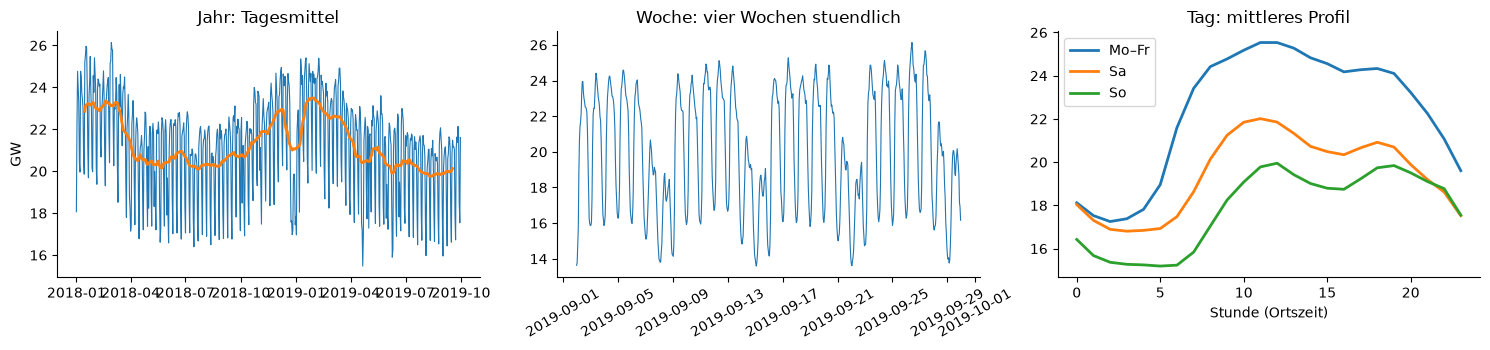

✅ 1.2 Tagesprofil Mo–Fr: Maximum zwischen 10 und 13 Uhr


In [3]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Drei Zeitskalen in drei Bildern: links Jahr (Tagesmittel + 4-Wochen-Mittel), Mitte vier Wochen stuendlich,
# 🎓 rechts mittleres Tagesprofil getrennt nach Mo–Fr / Sa / So. Alles nur auf dem Trainingszeitraum, in GW (/1000).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
tr = y.loc[:TRAIN_END] / 1000                             # Trainingszeitraum, in GW
kal_tr = kal.loc[:TRAIN_END]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
# 🎓 resample('D').mean(): 24 Stundenwerte -> 1 Tagesmittel; rolling(28, center=True): 4-Wochen-Mittel = Jahresgang.
tag = tr.resample("D").mean()                              # Tagesmittel
axs[0].plot(tag, lw=0.8); axs[0].plot(tag.rolling(28, center=True).mean(), lw=2)   # plus gleitendes 4-Wochen-Mittel
axs[0].set_title("Jahr: Tagesmittel"); axs[0].set_ylabel("GW")
# 🎓 2.9.–29.9.2019 = genau vier Wochen Montag bis Sonntag -> Wochenmuster gut sichtbar.
axs[1].plot(tr.loc["2019-09-02":"2019-09-29"], lw=0.8); axs[1].set_title("Woche: vier Wochen stuendlich")
axs[1].tick_params(axis="x", rotation=30)
# 🎓 maske = boolesche Series (True fuer die Stunden des jeweiligen Tagestyps); wochentag 0 = Mo ... 6 = So.
for name, maske in [("Mo–Fr", kal_tr.wochentag < 5), ("Sa", kal_tr.wochentag == 5), ("So", kal_tr.wochentag == 6)]:
    # TODO 1.2 (Loesung): profil = mittlere Last je Stunde (Ortszeit) fuer die Tage in `maske`: tr[maske].groupby(...).mean()
    # 🎓 tr[maske] behaelt nur die Stunden dieses Tagestyps; groupby nach der Ortszeit-Stunde (ebenfalls maskiert,
    # 🎓 damit beide gleich lang sind) -> 24 Mittelwerte, Index 0..23.
    profil = tr[maske].groupby(kal_tr.stunde[maske]).mean()   # Mittelwert je Stunde 0..23
    axs[2].plot(profil.index, profil.values, lw=2, label=name)
axs[2].set_title("Tag: mittleres Profil"); axs[2].set_xlabel("Stunde (Ortszeit)"); axs[2].legend()
plt.tight_layout(); plt.show()
check("1.2 Tagesprofil Mo–Fr: Maximum zwischen 10 und 13 Uhr",
      lambda: 10 <= tr[kal_tr.wochentag < 5].groupby(kal_tr.stunde[kal_tr.wochentag < 5]).mean().idxmax() <= 13)

### 1.3 · Autokorrelation selbst berechnen

`CODE` (1 Zeile) · Wie stark hängt die Last von ihrem eigenen Wert vor $k$ Stunden ab?

$$r_k = \frac{\sum_{t=k+1}^{T} (y_t - \bar y)(y_{t-k} - \bar y)}{\sum_{t=1}^{T} (y_t - \bar y)^2}$$

**So liest man die Formel:** Zähler = Summe der Produkte der Abweichungen vom Mittelwert *jetzt* und *vor k Stunden*; Nenner normiert,
sodass $r_0 = 1$. In NumPy: Mit `d = x - x.mean()` ist der Zähler `np.dot(d[:-k], d[k:])` – die Reihe ohne die letzten k Werte mal
die Reihe ohne die ersten k Werte.
**Erwartung (Training):** $r_1 = 0{,}967$ · $r_{12} = -0{,}034$ · $r_{24} = 0{,}761$ · $r_{168} = 0{,}884$.

{1: np.float64(0.967), 12: np.float64(-0.034), 24: np.float64(0.761), 168: np.float64(0.884), 336: np.float64(0.847), 8760: np.float64(0.313)}
✅ 1.3 r_1 = 0,967 und r_24 = 0,761
✅ 1.3 r_168 = 0,884 (Vorwoche schlaegt Vortag)


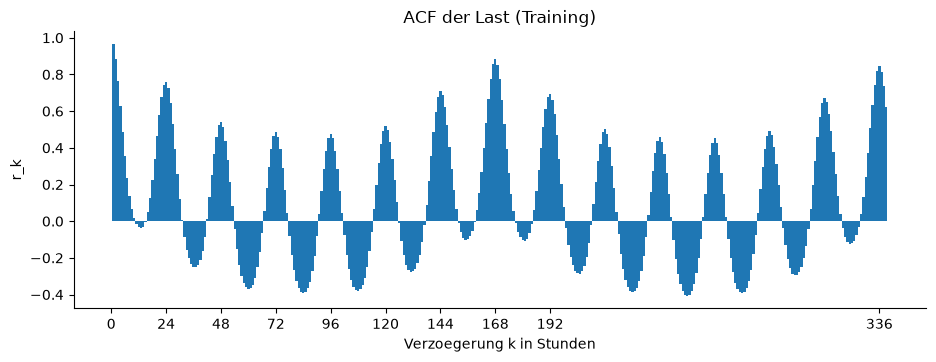

In [4]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Autokorrelation 'von Hand': Wie aehnlich ist die Reihe sich selbst, um k Stunden verschoben?
# 🎓 Kernidee des Array-Schnitts: Wir legen die Reihe zweimal untereinander, eine davon um k verschoben, und multiplizieren paarweise.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
def acf(x, k):
    """Autokorrelation der Reihe x (NumPy-Array) bei Verzoegerung k (k >= 1)."""
    d = x - x.mean()                                      # Abweichungen vom Mittelwert
    # TODO 1.3 (Loesung): Zaehler durch Nenner: np.dot(d[:-k], d[k:]) / np.dot(d, d)
    # 🎓 SCHNITT: d = [d_0, d_1, ..., d_{T-1}]   (T Werte)
    # 🎓   d[:-k] = [d_0,  ..., d_{T-1-k}]  -> Reihe OHNE die letzten k Werte  = 'frueher'  (Zeitpunkte t)
    # 🎓   d[k:]  = [d_k,  ..., d_{T-1}]    -> Reihe OHNE die ersten  k Werte  = 'spaeter'  (Zeitpunkte t + k)
    # 🎓   Beide haben Laenge T-k; Element i passt zu Element i -> Paare (d_t, d_{t+k}) = genau die Paare mit Abstand k.
    # 🎓   np.dot = Summe dieser Produkte (Zaehler). Nenner np.dot(d, d) = Summe der Quadrate ueber ALLE T Werte -> r_0 = 1.
    # 🎓   Beispiel k = 2, T = 5: d[:-2] = [d0, d1, d2], d[2:] = [d2, d3, d4] -> d0·d2 + d1·d3 + d2·d4.
    # 🎓   (k = 0 geht so nicht: d[:-0] = d[:0] ist leer – deshalb k >= 1.)
    return np.dot(d[:-k], d[k:]) / np.dot(d, d)

x_tr = y.loc[:TRAIN_END].values
# 🎓 k = 1 (Vorstunde), 12 (halber Tag, ~0), 24 (Vortag), 168 (Vorwoche), 336 (zwei Wochen), 8760 (Vorjahr).
werte = {k: acf(x_tr, k) for k in [1, 12, 24, 168, 336, 8760]}
print({k: round(v, 3) for k, v in werte.items()})
check("1.3 r_1 = 0,967 und r_24 = 0,761", lambda: nah(acf(x_tr, 1), 0.967, 0.001) and nah(acf(x_tr, 24), 0.761, 0.001))
check("1.3 r_168 = 0,884 (Vorwoche schlaegt Vortag)", lambda: nah(acf(x_tr, 168), 0.884, 0.001))

# 🎓 Balkendiagramm fuer k = 1..339 (gut zwei Wochen): Spitzen bei 24, 48, ... und die hoechste bei 168.
lags = np.arange(1, 340)
plt.bar(lags, [acf(x_tr, k) for k in lags], width=1); plt.xticks([0, 24, 48, 72, 96, 120, 144, 168, 192, 336])
plt.xlabel("Verzoegerung k in Stunden"); plt.ylabel("r_k"); plt.title("ACF der Last (Training)"); plt.show()
save_log("a1_acf", **{f"r_{k}": v for k, v in werte.items()})

### 1.4 · MSTL-Zerlegung

`AUSFÜHREN` · `MSTL` zerlegt acht Wochen (5.8.–29.9.2019) in Trend + Tagessaison (24 h) + Wochensaison (168 h) + Rest.
**Erwartung:** Varianzanteile Tagessaison ≈ 0,66 · Wochensaison ≈ 0,34 · Trend und Rest je ≈ 0,01.

Varianzanteile: {'data': 1.0, 'trend': 0.01, 'seasonal24': 0.661, 'seasonal168': 0.335, 'remainder': 0.011}


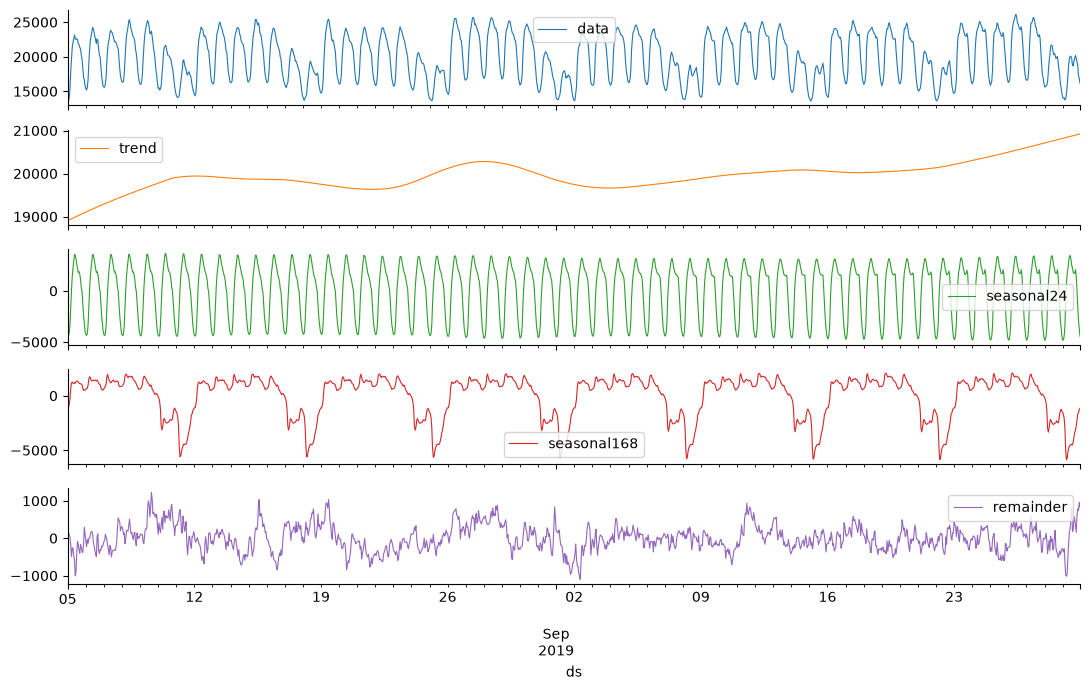

✅ 1.4 Tagessaison ≈ 66 %, Wochensaison ≈ 34 % der Varianz


In [5]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 MSTL-Zerlegung von acht Wochen: Mo 5.8. bis So 29.9.2019 = 56 Tage = 1 344 Stunden (Ende = Trainingsende).
# 🎓 Ergebnis: data = trend + seasonal24 + seasonal168 + remainder. Varianzanteil = var(Komponente) / var(Original).
# 🎓 Die Anteile summieren sich nicht exakt zu 1 (Kovarianzen zwischen den Komponenten).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
fenster = y.loc["2019-08-05":"2019-09-29 23:00"]
# 🎓 statsforecast will 'lange' Tabellen: Spalten unique_id (welche Reihe), ds (Zeit), y (Wert).
sdf = pd.DataFrame({"unique_id": "amprion", "ds": fenster.index, "y": fenster.values})   # Format von statsforecast
sf = StatsForecast(models=[MSTL(season_length=[24, 168])], freq="h").fit(sdf)
# 🎓 fitted_[0, 0] = erste Reihe (es gibt nur 'amprion'), erstes Modell (nur MSTL); .model_ = Komponententabelle.
zerl = sf.fitted_[0, 0].model_                               # Tabelle: data, trend, seasonal24, seasonal168, remainder
anteile = (zerl.var() / fenster.var()).round(3)
print("Varianzanteile:", anteile.to_dict())
# 🎓 Die Komponententabelle hat einen 0..N-Index -> Zeitindex des Fensters setzen, damit die x-Achse Datumswerte zeigt.
zerl.set_index(fenster.index).plot(subplots=True, figsize=(11, 7), lw=0.8, legend=True); plt.tight_layout(); plt.show()
check("1.4 Tagessaison ≈ 66 %, Wochensaison ≈ 34 % der Varianz",
      nah(anteile["seasonal24"], 0.661, 0.01) and nah(anteile["seasonal168"], 0.335, 0.01))
save_log("a1_mstl", **anteile.to_dict())

**`DENKEN` – Interpretation**

a) Warum ist $r_{168} > r_{24}$? Was vergleicht der Vortag am Montag?
b) Was würde ein Modell, das nur die Tagessaison kennt, systematisch falsch machen?
c) Wo ist der Rest der Zerlegung groß – und was könnte dort passiert sein?

*Lösung:* a) Die Vorwoche vergleicht denselben Wochentag zur selben Stunde; der Vortag vergleicht am Montag mit dem Sonntag und am
Samstag mit dem Freitag. b) Es überträgt das Niveau des Vortags: Montag zu niedrig, Samstag zu hoch. c) Am Ende des Fensters (Montag
30.9. fehlt noch, aber Wochenwechsel und Sonderfälle) und an Tagen, die nicht ins Wochenmuster passen – Vorgriff auf Abschnitt 5.

## Aufgabe 2 · Baselines und Backtest

**Block nach „Die Messlatte“ · 15 Min.** · Folien Abschnitt 2 · FPP3 Kap. 5.2, 5.8, 5.10

### 2.1 · Fehlermaße als Funktionen

`CODE` (je 1 Zeile) · Mit $e_t = y_t - \hat y_t$ (Ist minus Prognose):

$$\mathrm{MAE} = \tfrac1n \textstyle\sum_t |e_t| \qquad \mathrm{RMSE} = \sqrt{\tfrac1n \sum_t e_t^2} \qquad
\mathrm{MAPE} = \tfrac{100\,\%}{n} \sum_t \left|\tfrac{e_t}{y_t}\right| \qquad
\mathrm{MASE} = \frac{\mathrm{MAE}}{q},\ q = \tfrac{1}{T-m}\textstyle\sum_{t=m+1}^{T} |y_t - y_{t-m}|$$

`mase` ist vorgegeben (Maßstab $q$ = MAE der saisonal-naiven Prognose mit $m = 168$ im Training).
**Erwartung (Folienbeispiel A):** MAE 1,25 · RMSE 1,50 · MAPE 6,03 % · Maßstab $q$ = 1 063 MW.

In [6]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Fehlermasse als Funktionen + Massstab fuer MASE + bewerte() (eine Tabellenzeile je Modell, wird ueberall genutzt).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 2")
def mae(ist, prog):
    # TODO 2.1a (Loesung): mittlerer absoluter Fehler: np.mean(np.abs(ist - prog))
    return float(np.mean(np.abs(ist - prog)))

def rmse(ist, prog):
    # TODO 2.1b (Loesung): Wurzel des mittleren quadratischen Fehlers
    return float(np.sqrt(np.mean((ist - prog) ** 2)))

def mape(ist, prog):
    # TODO 2.1c (Loesung): mittlerer absoluter prozentualer Fehler in Prozent
    return float(np.mean(np.abs((ist - prog) / ist)) * 100)

# 🎓 SCHNITT fuer den MASE-Massstab q (x_tr = Trainingsreihe als NumPy-Array, Laenge T):
# 🎓   x_tr[168:]  = Werte ab Stunde 168  -> 'jetzt'      (y_t,      t = 168 .. T-1)
# 🎓   x_tr[:-168] = Werte bis T-169     -> 'vor 1 Woche' (y_{t-168})
# 🎓   Differenz = Fehler der saisonal-naiven Prognose im Training; Mittel der Betraege = deren MAE = q (≈ 1 063 MW).
# 🎓   MASE < 1 heisst also: besser als 'Vorwoche kopieren' im Training.
Q_MASE = float(np.mean(np.abs(x_tr[168:] - x_tr[:-168])))    # MAE von "Vorwoche kopieren" im Training
def mase(ist, prog):
    return mae(ist, prog) / Q_MASE

def bewerte(name, prognose):
    """Vergleicht eine Prognose (Series mit Zeitindex) mit der Ist-Last und gibt eine Tabellenzeile zurueck."""
    # 🎓 Holt die Ist-Werte zu genau den Zeitstempeln der Prognose -> Prognosen duerfen beliebige Zeitraeume haben.
    ist = y.loc[prognose.index].values; p = np.asarray(prognose, dtype=float)
    return {"Modell": name, "MAE": round(mae(ist, p)), "RMSE": round(rmse(ist, p)), "MAPE": round(mape(ist, p), 2),
            "MASE": round(mase(ist, p), 3)}

# 🎓 Folienbeispiel A: 4 Werte, Fehler [-1, 0, 2, -2] -> MAE 5/4 = 1,25; RMSE sqrt(9/4) = 1,5.
a, pA = np.array([20, 22, 25, 18.]), np.array([21, 22, 23, 20.])
check("2.1 Folienbeispiel A: MAE 1,25 · RMSE 1,50 · MAPE 6,03 %",
      lambda: nah(mae(a, pA), 1.25, 1e-9) and nah(rmse(a, pA), 1.5, 1e-9) and nah(mape(a, pA), 6.03, 0.01))
print(f"Massstab q fuer MASE: {Q_MASE:.0f} MW")

✅ 2.1 Folienbeispiel A: MAE 1,25 · RMSE 1,50 · MAPE 6,03 %
Massstab q fuer MASE: 1063 MW


### 2.2 · Baselines im Backtest

`CODE` (2 Zeilen) · Zwei einfache Prognosen als Messlatte: **naiv** (gleiche Stunde gestern, $\hat y_t = y_{t-24}$) und
**saisonal naiv** (gleiche Stunde vor einer Woche, $\hat y_t = y_{t-168}$). In pandas verschiebt `y.shift(24)` die ganze Reihe um 24
Stunden nach hinten. Schneiden Sie beide auf die Backtest-Stunden `BT_INDEX` zu.
**Erwartung:** naiv MAE 1 562 MW · saisonal naiv 927 MW · Netzbetreiber 466 MW.

In [7]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Zwei Baselines + Prognose des Netzbetreibers, jeweils auf die 672 Backtest-Stunden zugeschnitten.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
# TODO 2.2 (Loesung): p_naiv = y.shift(24) auf BT_INDEX, p_snaiv = y.shift(168) auf BT_INDEX
# 🎓 y.shift(24): Wert, der bei t steht, ist danach der Wert von t-24 (Reihe rutscht 24 h 'nach hinten', vorne NaN).
# 🎓 .loc[BT_INDEX] schneidet daraus genau die 672 Backtest-Stunden aus.
# 🎓 Leckagefrei: fuer 23:00 des Prognosetags wird 23:00 des Vortags genommen = juengster Wert zum Ursprung.
p_naiv  = y.shift(24).loc[BT_INDEX]                        # gleiche Stunde gestern
p_snaiv = y.shift(168).loc[BT_INDEX]                       # gleiche Stunde vor einer Woche
# 🎓 Day-ahead-Prognose des Netzbetreibers aus dem Datensatz = 'Profi-Messlatte' (466 MW).
p_tso = df["load_forecast_tso_mw"].astype(float).loc[BT_INDEX]   # Day-ahead-Prognose des Netzbetreibers

# 🎓 ERGEBNISSE ist eine globale Liste; jede spaetere Aufgabe haengt Zeilen an (Achtung: Zelle 2x ausfuehren = doppelte Zeilen,
# 🎓 wird erst in 5.3 per drop_duplicates bereinigt).
ERGEBNISSE = [bewerte("Naiv (Vortag)", p_naiv), bewerte("Saisonal naiv (Vorwoche)", p_snaiv),
              bewerte("Netzbetreiber (Day-ahead)", p_tso)]
display(pd.DataFrame(ERGEBNISSE).set_index("Modell"))
check("2.2 naiv 1 562 MW, saisonal naiv 927 MW", lambda: ERGEBNISSE[0]["MAE"] == 1562 and ERGEBNISSE[1]["MAE"] == 927)
save_log("a2_baselines", ergebnisse=ERGEBNISSE)

,MAE,RMSE,MAPE,MASE
Modell,,,,
Naiv (Vortag),1562,2350,7.64,1.469
Saisonal naiv (Vorwoche),927,1467,4.43,0.872
Netzbetreiber (Day-ahead),466,574,2.29,0.438


✅ 2.2 naiv 1 562 MW, saisonal naiv 927 MW


### 2.3 · Das Backtest-Gerüst

`LIVE` · Statistische Modelle werden an **jedem** der 28 Ursprünge neu geschätzt – nur mit den Daten bis 23:00 Uhr des Vortags
(`fenster` Stunden zurück) – und sagen dann 24 Stunden voraus. Die Funktion `backtest()` übernimmt das für alle Modelle in Aufgabe 3.
**Probe:** `SeasonalNaive(168)` im Backtest muss genau die Werte von `y.shift(168)` liefern (927 MW).

✅ 2.3 backtest() mit SeasonalNaive(168) = y.shift(168): 927 MW


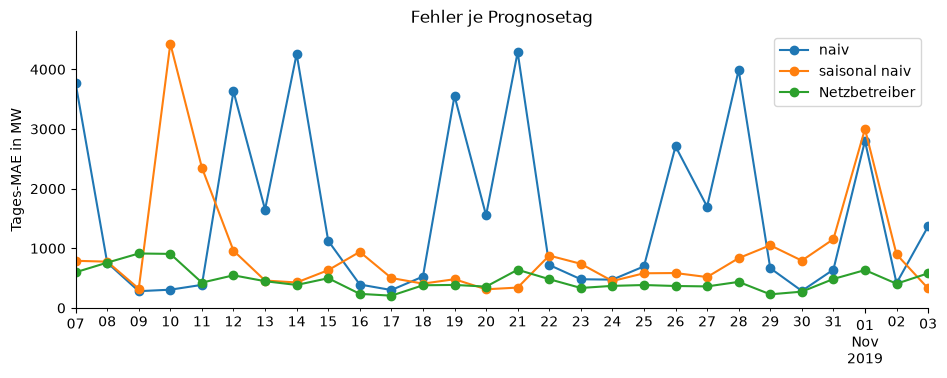

In [8]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Backtest mit rollierendem Ursprung fuer statsforecast-Modelle: 28-mal neu schaetzen, je 24 h vorhersagen, aneinanderhaengen.
# 🎓 Wird in A3 fuer ETS, SARIMA und MSTL wiederverwendet. Probe: SeasonalNaive(168) muss exakt y.shift(168) ergeben.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
def backtest(modelle, fenster=4 * 168):
    """Rollierender Ursprung: fuer jeden Prognosetag mit den letzten `fenster` Stunden schaetzen, 24 Stunden vorhersagen."""
    prognosen = []
    for o in URSPRUENGE:
        # TODO 2.3 (Loesung): Historie bis o - 1 h (letzte `fenster` Werte), ins statsforecast-Format, forecast(h=24), anhaengen
        # 🎓 SCHNITT in zwei Schritten (o = 00:00 UTC des Prognosetags):
        # 🎓   y.loc[:o - 1 h]  -> alle Werte von 1.1.2018 BIS EINSCHLIESSLICH 23:00 des Vortags (.loc mit Zeit: Ende inklusive!)
        # 🎓   .iloc[-fenster:] -> davon nur die letzten `fenster` Positionen (Standard 4 x 168 = 672 h = die letzten 4 Wochen).
        # 🎓   Warum nicht alles? Statistische Modelle sollen sich an das aktuelle Niveau anpassen; ausserdem schneller.
        hist = y.loc[:o - pd.Timedelta(hours=1)].iloc[-fenster:]      # nur Vergangenheit: bis 23:00 des Vortags
        sdf = pd.DataFrame({"unique_id": "amprion", "ds": hist.index, "y": hist.values})
        # 🎓 forecast(h=24): schaetzt das Modell auf hist und gibt die 24 Stunden o .. o+23 zurueck (Spalten: unique_id, ds, <Modell>).
        f = StatsForecast(models=modelle, freq="h").forecast(df=sdf, h=24)   # 24 Stunden ab o
        # 🎓 ds als Index, unique_id weg -> uebrig bleibt je Modell eine Spalte mit 24 Werten.
        prognosen.append(f.set_index("ds").drop(columns="unique_id"))
    # 🎓 concat: 28 Bloecke x 24 h = 672 Zeilen; .iloc[:, 0] = erste Spalte als Series (wir uebergeben immer nur ein Modell).
    return pd.concat(prognosen).iloc[:, 0]                 # eine Spalte = Prognosen des (ersten) Modells

p_test = backtest([SeasonalNaive(season_length=168)])
check("2.3 backtest() mit SeasonalNaive(168) = y.shift(168): 927 MW", lambda: bewerte("t", p_test)["MAE"] == 927)

# 🎓 Absolute Fehler je Stunde, dann resample('D').mean() -> Tages-MAE je Prognosetag (28 Punkte je Linie).
# 🎓 Im Plot: Montage hoch fuer 'naiv' (erbt Sonntag), Fr 1.11. hoch fuer alle Baselines (Allerheiligen).
fehler_tag = pd.DataFrame({"naiv": (y.loc[BT_INDEX] - p_naiv).abs(), "saisonal naiv": (y.loc[BT_INDEX] - p_snaiv).abs(),
                           "Netzbetreiber": (y.loc[BT_INDEX] - p_tso).abs()}).resample("D").mean()
fehler_tag.plot(marker="o", ylabel="Tages-MAE in MW", title="Fehler je Prognosetag"); plt.show()

**`DENKEN` – Interpretation**

a) Warum ist die naive Prognose montags so schlecht? b) Was passiert am Freitag, 1.11.2019? c) Warum liegt die MASE der
saisonal-naiven Prognose im Backtest unter 1, obwohl sie die Baseline selbst ist?

*Lösung:* a) Montag erbt den Sonntag (≈ 4 GW weniger). b) Allerheiligen – Feiertag in NRW, BW, BY, RP, SL; alle Baselines erwarten
einen normalen Freitag. c) Der Nenner $q$ stammt aus dem Training (2018–9/2019, inkl. Feiertage und Ferien); der Oktober ist ruhiger.

## Aufgabe 3 · ETS, SARIMA und MSTL

**Block nach „Zwischenstand: Klassische Modelle“ · 15 Min.** · Folien Abschnitt 3 · FPP3 Kap. 8, 9, 12.1

### 3.1 · ETS: Automatik gegen Vorgabe

`CODE` (1 Zeile) · `AutoETS(season_length=24)` wählt die ETS-Variante selbst nach dem kleinsten AICc. Die erste Zelle zeigt, was
die Automatik am ersten Ursprung wählt. Danach: Backtest mit **fest vorgegebener** Variante `model="ANA"` (additiver Fehler,
kein Trend, additive Saison mit Periode 24).
**Erwartung:** Die Automatik wählt ETS(A,Ad,N) – **ohne Saison**. Im Backtest: automatisch 4 778 MW · fest ETS(A,N,A) 1 758 MW.

In [9]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 ETS: zuerst zeigen, was AutoETS am ersten Ursprung waehlt (ETS(A,Ad,N) – Saison fehlt!), dann zwei Backtests:
# 🎓 Automatik (4 778 MW, katastrophal) gegen fest vorgegebenes ETS(A,N,A) mit Tagessaison (1 758 MW).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 3")
# 🎓 Exakt derselbe Schnitt wie in backtest(): die 4 Wochen bis 6.10.2019 23:00 (erster Ursprung).
hist = y.loc[:URSPRUENGE[0] - pd.Timedelta(hours=1)].iloc[-4 * 168:]
sf = StatsForecast(models=[AutoETS(season_length=24)], freq="h").fit(pd.DataFrame({"unique_id": "a", "ds": hist.index, "y": hist.values}))
# 🎓 model_['method'] = Text der gewaehlten Variante: (Fehler, Trend, Saison) – A = additiv, Ad = gedaempft, N = keine.
print("AutoETS waehlt am 7.10.2019:", sf.fitted_[0, 0].model_["method"])

p_ets_auto = backtest([AutoETS(season_length=24)])
# TODO 3.1 (Loesung): p_ets = backtest(...) mit AutoETS(season_length=24, model="ANA")
p_ets = backtest([AutoETS(season_length=24, model="ANA")])
# 🎓 Beide Ergebnisse an die Vergleichstabelle anhaengen und sofort ausgeben.
for name, p in [("AutoETS (Automatik)", p_ets_auto), ("ETS(A,N,A), s = 24", p_ets)]:
    ERGEBNISSE.append(bewerte(name, p)); print(ERGEBNISSE[-1])
check("3.1 ETS(A,N,A): MAE 1.758 MW", lambda: nah(bewerte("t", p_ets)["MAE"], 1758, 2))

AutoETS waehlt am 7.10.2019: ETS(A,Ad,N)


{'Modell': 'AutoETS (Automatik)', 'MAE': 4778, 'RMSE': 6239, 'MAPE': 20.93, 'MASE': 4.494}
{'Modell': 'ETS(A,N,A), s = 24', 'MAE': 1758, 'RMSE': 2255, 'MAPE': 8.65, 'MASE': 1.654}
✅ 3.1 ETS(A,N,A): MAE 1.758 MW


### 3.2 · SARIMA im Backtest

`LIVE` · Ordnung $(3,0,0)(2,1,0)_{24}$: einmal saisonal differenzieren ($y_t - y_{t-24}$), dann AR(3) auf die letzten drei Stunden
und saisonales AR(2) auf $t-24$ und $t-48$. Die Ordnung wurde einmal mit AutoARIMA bestimmt und wird fest übernommen (≈ 20 s
Rechenzeit – AutoARIMA an jedem Ursprung würde zu lange dauern). **Erwartung:** 1 620 MW.

In [10]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 SARIMA mit fest vorgegebener Ordnung im Backtest (≈ 20 s). (3,0,0) = AR(3) auf die letzten drei Stunden,
# 🎓 (2,1,0)_24 = einmal saisonal differenzieren (y_t - y_{t-24}) + saisonales AR(2) auf t-24 und t-48. Erwartung 1 620 MW.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
t0 = time.time()
p_sarima = backtest([ARIMA(order=(3, 0, 0), seasonal_order=(2, 1, 0), season_length=24)])
ERGEBNISSE.append(bewerte("SARIMA(3,0,0)(2,1,0)24", p_sarima)); print(ERGEBNISSE[-1], f"| {time.time() - t0:.0f} s")
check("3.2 SARIMA: MAE 1 620 MW", lambda: nah(ERGEBNISSE[-1]["MAE"], 1620, 3))

{'Modell': 'SARIMA(3,0,0)(2,1,0)24', 'MAE': 1620, 'RMSE': 2132, 'MAPE': 7.78, 'MASE': 1.523} | 11 s
✅ 3.2 SARIMA: MAE 1 620 MW


### 3.3 · MSTL mit zwei Saisons

`CODE` (1 Zeile) · `MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN"))` zieht beide Saisons ab, schreibt den Rest
mit einem ETS ohne Saison fort und addiert die Saisons wieder. Fenster **8 Wochen** (`fenster=8 * 168`), damit die Wochensaison
mehrfach vorkommt. **Erwartung:** 673 MW – deutlich besser als saisonal naiv (927 MW).

{'Modell': 'MSTL + ETS', 'MAE': 673, 'RMSE': 987, 'MAPE': 3.26, 'MASE': 0.633}
✅ 3.3 MSTL: MAE 673 MW


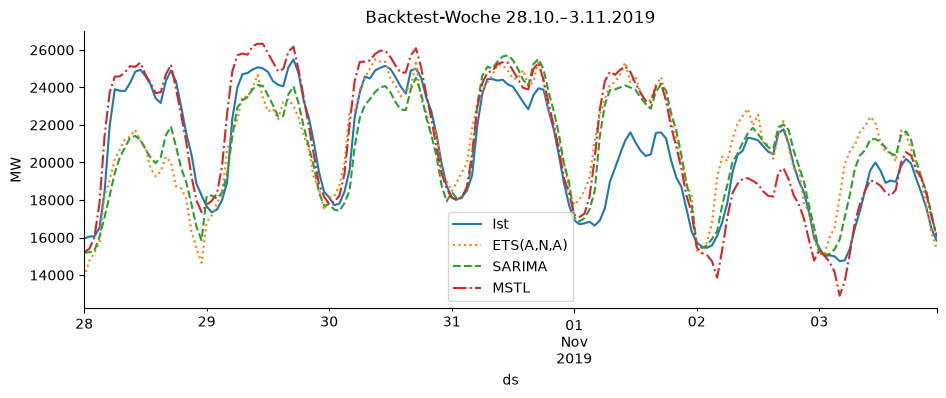

,MAE,RMSE,MAPE,MASE
Modell,,,,
Naiv (Vortag),1562,2350,7.64,1.469
Saisonal naiv (Vorwoche),927,1467,4.43,0.872
Netzbetreiber (Day-ahead),466,574,2.29,0.438
AutoETS (Automatik),4778,6239,20.93,4.494
"ETS(A,N,A), s = 24",1758,2255,8.65,1.654
"SARIMA(3,0,0)(2,1,0)24",1620,2132,7.78,1.523
MSTL + ETS,673,987,3.26,0.633


In [11]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 MSTL + ETS im Backtest (Fenster 8 Wochen statt 4, damit die Wochensaison 168 h achtmal vorkommt).
# 🎓 MSTL zieht Tages- und Wochensaison ab, ETS 'ZZN' (Fehler/Trend automatisch, keine Saison) schreibt den Rest fort,
# 🎓 dann werden die Saisons wieder addiert. Erwartung 673 MW – erstes Modell deutlich besser als saisonal naiv (927).
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
# TODO 3.3 (Loesung): p_mstl = backtest([MSTL(...)], fenster=8 * 168)
p_mstl = backtest([MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN"))], fenster=8 * 168)
ERGEBNISSE.append(bewerte("MSTL + ETS", p_mstl)); print(ERGEBNISSE[-1])
check("3.3 MSTL: MAE 673 MW", lambda: nah(bewerte("t", p_mstl)["MAE"], 673, 3))

# 🎓 w = Zeitfenster fuer die Plots (wird auch in 4.3 und 5.2 benutzt!): Mo 28.10. bis So 3.11.2019, die letzte Backtest-Woche
# 🎓 mit Allerheiligen (Fr 1.11.). slice auf einem Zeitindex: .loc[w] schneidet inklusive beider Enden.
w = slice("2019-10-28", "2019-11-03 23:00")                 # eine Woche mit Allerheiligen
pd.DataFrame({"Ist": y.loc[w], "ETS(A,N,A)": p_ets.loc[w], "SARIMA": p_sarima.loc[w], "MSTL": p_mstl.loc[w]}).plot(
    style=["-", ":", "--", "-."], ylabel="MW", title="Backtest-Woche 28.10.–3.11.2019"); plt.show()
# 🎓 Zwischenstand der Vergleichstabelle nach den klassischen Modellen.
display(pd.DataFrame(ERGEBNISSE).set_index("Modell"))
save_log("a3_statistik", ergebnisse=ERGEBNISSE)

**`DENKEN` – Interpretation**

a) Warum ist ETS(A,N,A) sogar schlechter als die naive Prognose? b) Warum braucht MSTL ein längeres Fenster? c) Was lehrt die
Wahl der Automatik in 3.1 über automatische Modellwahl?

*Lösung:* a) Die Saison mit Periode 24 passt sich über $\gamma$ an die letzten Tage an – am Montag erbt sie den Sonntag, zusätzlich
geglättet; die Wochenstruktur fehlt. b) Die Wochensaison (168 h) muss mehrmals im Fenster vorkommen, um geschätzt zu werden.
c) Die Automatik optimiert AICc – 24 Saisonzustände kosten Strafe, deshalb fällt die Saison heraus. Kriterium erfüllt, Ziel verfehlt:
Ergebnis immer plotten und mit Baselines vergleichen.

## Aufgabe 4 · LightGBM und LSTM

**Block nach „Ein LSTM für 24 Stunden“ · 15 Min.** · Folien Abschnitt 4 · Géron Kap. 15

### 4.1 · Merkmale leckagefrei bauen

`CODE` (2 Zeilen) · Jede Stunde wird eine Tabellenzeile: Kalender (Ortszeit) plus Lags. Ergänzen Sie in `merkmale()` die
**Lags 24, 48, 168 und 336 Stunden** (Spaltennamen `lag_24`, …) und das **Mittel der 24 Stunden bis t − 24**
(`mittel_24_lag24` = gleitendes Mittel über 24 Werte von `y.shift(24)`).
**Wichtig:** Kein Lag unter 24 h und das gleitende Mittel auf `y.shift(24)`, nicht auf `y` – sonst steckt die Zielstunde im Merkmal.

In [12]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Merkmalstabelle fuer LightGBM: eine Zeile je Stunde = 4 Kalendermerkmale + 4 Lags + 1 gleitendes Mittel = 9 Spalten.
# 🎓 Leckage-Regel: Jedes Merkmal einer Zielstunde des Tages D darf nur Werte bis 23:00 von D-1 enthalten -> alle Lags >= 24 h.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 4")
def merkmale(y):
    X = kalender(y.index)                                  # stunde, wochentag, monat, feiertag
    #<TODO 4.1 | Lags 24, 48, 168, 336 als Spalten lag_<l>; mittel_24_lag24 = y.shift(24).rolling(24).mean()>
    for l in [24, 48, 168, 336]:
        # 🎓 lag_24 = gleiche Stunde gestern, lag_48 = vorgestern, lag_168 = vor 1 Woche, lag_336 = vor 2 Wochen.
        X[f"lag_{l}"] = y.shift(l)                         # Wert vor l Stunden (l >= 24 -> zum Ursprung bekannt)
    # 🎓 ERST verschieben, DANN mitteln: y.shift(24) steht bei t fuer y_{t-24}; rolling(24) mittelt die 24 Positionen t-23..t
    # 🎓 dieser verschobenen Reihe -> Mittel von y_{t-47} .. y_{t-24}. Fuer 23:00 von D ist das genau der ganze Vortag.
    # 🎓 Falsch waere y.rolling(24).mean().shift(0): dann steckt y_t (die Zielstunde selbst) im Merkmal.
    X["mittel_24_lag24"] = y.shift(24).rolling(24).mean()  # Niveau des Vortags
    #</TODO>
    return X

X = merkmale(y)
# 🎓 Boolesche Maske: Zeile liegt im Training UND hat keine NaN (die ersten 336 Stunden fehlen wegen lag_336).
maske_train = (X.index <= TRAIN_END) & X.notna().all(axis=1)   # Trainingszeilen mit vollstaendigen Lags
print(f"{maske_train.sum()} Trainingszeilen, {X.shape[1]} Merkmale: {list(X.columns)}")
# Leckage-Probe: aendert man y ab dem Ursprung, duerfen sich die Merkmale der Zielstunden nicht aendern
# 🎓 Leckage-Probe: Ab 7.10. 00:00 alle Ist-Werte um +1 000 000 MW verfaelschen und Merkmale neu bauen.
# 🎓 Wenn sich die Merkmale fuer den 7.10. (00:00–23:00) NICHT aendern, benutzen sie nur Werte bis 6.10. 23:00.
y_test = y.copy(); y_test.loc["2019-10-07":] += 1e6
check("4.1 Merkmale leckagefrei (Zielstunden haengen nur von Werten bis 23:00 des Vortags ab)",
      lambda: merkmale(y_test).loc["2019-10-07 00:00":"2019-10-07 23:00"].equals(X.loc["2019-10-07 00:00":"2019-10-07 23:00"]))
check("4.1 neun Merkmale", lambda: X.shape[1] == 9)

14976 Trainingszeilen, 9 Merkmale: ['stunde', 'wochentag', 'monat', 'feiertag', 'lag_24', 'lag_48', 'lag_168', 'lag_336', 'mittel_24_lag24']
✅ 4.1 Merkmale leckagefrei (Zielstunden haengen nur von Werten bis 23:00 des Vortags ab)
✅ 4.1 neun Merkmale


### 4.2 · LightGBM trainieren und deuten

`CODE` (2 Zeilen) · `LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=0, verbose=-1)` auf den
Trainingszeilen anpassen (`fit(X[maske_train], y[maske_train])`) und für `BT_INDEX` vorhersagen. Weil alle Lags ≥ 24 h sind, ist
jede Zeile direkt eine gültige Day-ahead-Prognose – keine Schleife über Ursprünge nötig.
**Erwartung:** MAE 488 MW (Netzbetreiber 466 MW), Training < 1 s.

Training + Vorhersage: 2.8 s
{'Modell': 'LightGBM', 'MAE': 488, 'RMSE': 616, 'MAPE': 2.4, 'MASE': 0.459}
✅ 4.2 LightGBM: MAE 488 MW


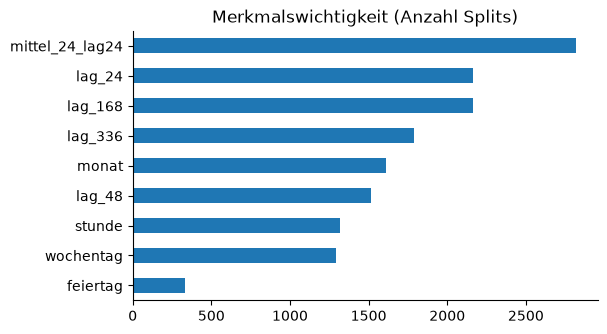

In [13]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 LightGBM einmal auf dem ganzen Training anpassen, dann direkt fuer alle 672 Backtest-Stunden vorhersagen.
# 🎓 Keine Schleife ueber Urspruenge noetig: Jede Zeile enthaelt nur Lags >= 24 h, ist also schon eine gueltige Day-ahead-Prognose.
# 🎓 (Unterschied zu A3: dort wurde an jedem Ursprung neu geschaetzt; hier bleibt das Modell auf Stand 30.9.2019.)
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
t0 = time.time()
# TODO 4.2 (Loesung): gbm anlegen und trainieren; p_gbm = pd.Series(gbm.predict(X.loc[BT_INDEX]), index=BT_INDEX)
gbm = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=0, verbose=-1)
# 🎓 Dieselbe boolesche Maske filtert Zeilen von X und y – beide haben denselben Zeitindex.
gbm.fit(X[maske_train], y[maske_train])
# 🎓 predict liefert ein NumPy-Array -> mit BT_INDEX wieder zur Zeitreihe machen (fuer bewerte() und Plots).
p_gbm = pd.Series(gbm.predict(X.loc[BT_INDEX]), index=BT_INDEX)
print(f"Training + Vorhersage: {time.time() - t0:.1f} s")
ERGEBNISSE.append(bewerte("LightGBM", p_gbm)); print(ERGEBNISSE[-1])
check("4.2 LightGBM: MAE 488 MW", lambda: nah(bewerte("t", p_gbm)["MAE"], 488, 5))
# 🎓 feature_importances_ = Anzahl Splits je Merkmal (nicht Wirkung!) – Vorlage fuer DENKEN-Frage c).
pd.Series(gbm.feature_importances_, index=X.columns).sort_values().plot.barh(
    title="Merkmalswichtigkeit (Anzahl Splits)", figsize=(6, 3.5)); plt.show()

### 4.3 · Ein LSTM für 24 Stunden

`LIVE` · Eingabe: die letzten **168 Stunden** mit vier Kanälen je Stunde – Last (standardisiert), $\sin$ und $\cos$ der Stunde,
Wochenend-Flag. Ein LSTM mit 32 Zuständen fasst die Woche zusammen, eine lineare Schicht gibt **24 Werte auf einmal** aus.
Training: Fenster alle 3 Stunden aus dem Trainingszeitraum, MSE-Verlust, Adam, 8 Epochen – die Trainingsschleife aus Woche 1.
**Erwartung:** 5 656 Parameter, Verlust fällt von ≈ 0,72 auf ≈ 0,11, MAE ≈ 745 MW, Training ≈ 10 s.

Parameter: 5656 | Trainingsfenster: 5041


Epoche 1: Verlust 0.7169 | 1.0 s


Epoche 2: Verlust 0.2794 | 2.1 s


Epoche 3: Verlust 0.1793 | 3.1 s


Epoche 4: Verlust 0.1367 | 4.1 s


Epoche 5: Verlust 0.1220 | 5.1 s


Epoche 6: Verlust 0.1151 | 6.2 s


Epoche 7: Verlust 0.1112 | 7.2 s


Epoche 8: Verlust 0.1070 | 8.2 s
{'Modell': 'LSTM', 'MAE': 745, 'RMSE': 953, 'MAPE': 3.57, 'MASE': 0.701}
✅ 4.3 LSTM: 5 656 Parameter, MAE unter 927 MW (saisonal naiv)


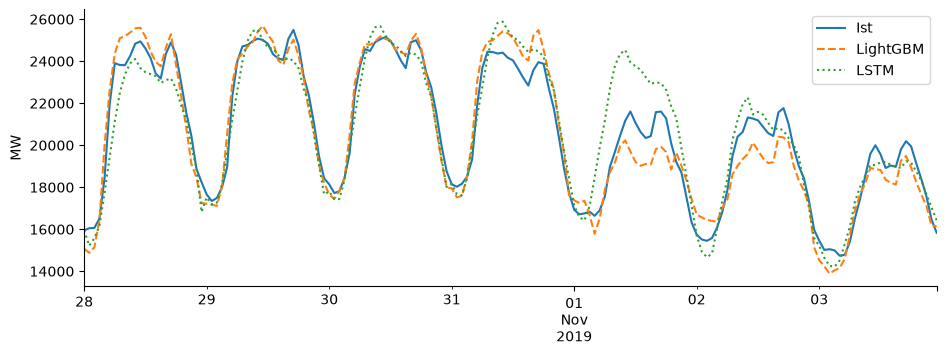

In [14]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 LSTM: Eingabe = letzte 168 h mit 4 Kanaelen (Last standardisiert, sin/cos der Stunde, Wochenend-Flag),
# 🎓 Ausgabe = 24 Werte auf einmal (die 24 Stunden des Folgetags). Ablauf: Merkmalsmatrix F bauen -> Fenster schneiden
# 🎓 -> Modell definieren -> 8 Epochen trainieren -> fuer die 28 Urspruenge vorhersagen -> zurueck in MW.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
torch.manual_seed(0)
# 🎓 Mittelwert/Streuung NUR aus dem Training (sonst Leckage), angewendet auf die ganze Reihe.
mu, sd = y.loc[:TRAIN_END].mean(), y.loc[:TRAIN_END].std()   # Standardisierung nur mit Trainingsstatistik
z = ((y - mu) / sd).values.astype(np.float32)
# 🎓 Stunde als Punkt auf dem Einheitskreis: 23 Uhr und 0 Uhr liegen nebeneinander (bei 0..23 als Zahl waeren sie 23 auseinander).
h_sin = np.sin(2 * np.pi * kal.stunde / 24).values           # Stunde als Kreis: 23 Uhr liegt neben 0 Uhr
h_cos = np.cos(2 * np.pi * kal.stunde / 24).values
we = (kal.wochentag >= 5).values.astype(float)               # Wochenende ja/nein
# 🎓 F: Zeile = Stunde (21 888), Spalte = Kanal (4). z zusaetzlich einzeln, weil es auch das Ziel ist.
F = np.stack([z, h_sin, h_cos, we], axis=1).astype(np.float32)   # 21 888 x 4
ENC, H = 168, 24

# 🎓 SCHNITT je Startposition s (= Position der ersten Zielstunde, also 00:00 UTC des Prognosetags):
# 🎓   F[s-168 : s]  -> Zeilen s-168 .. s-1  = die 168 Stunden VOR s (endet um 23:00 des Vortags = Ursprung)  -> Eingabe 168 x 4
# 🎓   z[s : s+24]   -> Positionen s .. s+23 = die 24 Stunden AB s (der Prognosetag)                           -> Ziel 24 Werte
# 🎓   Python-Schnitte schliessen das Ende aus -> Eingabe und Ziel ueberlappen nicht, kein Leck.
# 🎓   np.stack ueber viele s -> Xs: (Anzahl, 168, 4), Ys: (Anzahl, 24).
def fenster(starts):
    """Fuer jeden Startindex s: Eingabe F[s-168 : s] (168 x 4) und Ziel z[s : s+24] (24 Werte)."""
    Xs = np.stack([F[s - ENC:s] for s in starts]); Ys = np.stack([z[s:s + H] for s in starts])
    return torch.tensor(Xs), torch.tensor(Ys)

# 🎓 get_loc: Zeitstempel -> ganzzahlige Position (fuer NumPy-Schnitte noetig).
ende = y.index.get_loc(TRAIN_END)                            # Position der letzten Trainingsstunde
# 🎓 Startpositionen np.arange(ENC, ende - H + 2, 3):
# 🎓   erster Start s = 168 (vorher gibt es keine volle Woche Vergangenheit: F[0:168]),
# 🎓   letzter Start s = ende - 23 (arange schliesst das Ende ende - 22 aus) -> letztes Ziel z[ende-23 : ende+1] endet genau am 30.9. 23:00,
# 🎓   Schrittweite 3 h -> ueberlappende Fenster, ≈ 5 041 Trainingsbeispiele (jede Stunde waeren ≈ 15 000, langsamer, kaum besser).
Xtr, Ytr = fenster(np.arange(ENC, ende - H + 2, 3))          # Ziel endet spaetestens am 30.9. 23:00

class LSTMPrognose(torch.nn.Module):
    def __init__(self, n_in=4, hidden=32, H=24):
        super().__init__()
        self.lstm = torch.nn.LSTM(n_in, hidden, batch_first=True)   # laeuft ueber die 168 Schritte
        self.kopf = torch.nn.Linear(hidden, H)                     # letzter Zustand -> 24 Stunden
    def forward(self, x):
        # 🎓 LSTM liefert (Ausgaben aller 168 Schritte, (h, c)); wir brauchen nur h = letzter Zustand, Form (Schichten=1, Batch, 32).
        # 🎓 h[-1] = letzte Schicht -> (Batch, 32); der Kopf macht daraus (Batch, 24). Parameter: LSTM 4 864 + Linear 792 = 5 656.
        _, (h, _) = self.lstm(x)                                   # h: letzter verborgener Zustand
        return self.kopf(h[-1])

modell = LSTMPrognose()
print("Parameter:", sum(p.numel() for p in modell.parameters()), "| Trainingsfenster:", len(Xtr))
opt, lossf = torch.optim.Adam(modell.parameters(), lr=3e-3), torch.nn.MSELoss()
t0 = time.time()
for epoche in range(8):                                      # Trainingsschleife wie in Woche 1
    # 🎓 Je Epoche zufaellige Reihenfolge; perm[i:i+128] = Indizes des naechsten Mini-Batches (128 Fenster).
    modell.train(); perm = torch.randperm(len(Xtr)); summe = 0.0
    for i in range(0, len(Xtr), 128):
        b = perm[i:i + 128]
        opt.zero_grad(); verlust = lossf(modell(Xtr[b]), Ytr[b]); verlust.backward(); opt.step()
        # 🎓 Mit Batchgroesse gewichtet, damit der letzte (kleinere) Batch korrekt zaehlt -> Epochenmittel.
        summe += verlust.item() * len(b)
    print(f"Epoche {epoche + 1}: Verlust {summe / len(Xtr):.4f} | {time.time() - t0:.1f} s")

modell.eval()
# 🎓 Positionen der 28 Urspruenge (00:00 UTC) -> fenster(starts)[0] = nur die Eingaben (28, 168, 4); Ziele [1] ungenutzt.
starts = [y.index.get_loc(o) for o in URSPRUENGE]            # Ursprung = erste Stunde des Prognosetags
with torch.no_grad():
    # 🎓 Ausgabe (28, 24) standardisiert -> * sd + mu = zurueck in MW.
    P = modell(fenster(starts)[0]).numpy() * sd + mu          # zurueck in MW
# 🎓 ravel() liest zeilenweise: Tag 1 Std 0..23, Tag 2 Std 0..23, ... = genau die Reihenfolge von BT_INDEX.
p_lstm = pd.Series(P.ravel(), index=BT_INDEX)
ERGEBNISSE.append(bewerte("LSTM", p_lstm)); print(ERGEBNISSE[-1])
check("4.3 LSTM: 5 656 Parameter, MAE unter 927 MW (saisonal naiv)",
      lambda: sum(p.numel() for p in modell.parameters()) == 5656 and bewerte("t", p_lstm)["MAE"] < 927)
# 🎓 w = Woche 28.10.–3.11. (definiert in Zelle 3.3!). Vergleichsplot Ist / LightGBM / LSTM.
pd.DataFrame({"Ist": y.loc[w], "LightGBM": p_gbm.loc[w], "LSTM": p_lstm.loc[w]}).plot(style=["-", "--", ":"], ylabel="MW"); plt.show()
save_log("a4_ml", ergebnisse=ERGEBNISSE[-2:])

**`DENKEN` – Interpretation**

a) Welche Information hat LightGBM, die das LSTM nicht hat? b) Würde längeres Training dem LSTM viel helfen – was ist der eigentliche
Engpass? c) Die Merkmalswichtigkeit zählt Splits: Warum steht `feiertag` ganz unten, obwohl es an Allerheiligen entscheidend ist?

*Lösung:* a) Feiertag, Monat, Lag 336 und das Vortagesniveau als fertige Merkmale. b) Etwas – der Engpass sind die Daten: eine Reihe,
≈ 5 000 Fenster; das Netz muss Wochenstruktur und Feiertage selbst finden. c) Nur 18 Feiertage im Training → selten gesplittet,
aber mit großer Wirkung, wenn es greift. Split-Häufigkeit ≠ Einfluss (Erklärbarkeit mit SHAP: Thema Trustworthy AI).

## Aufgabe 5 · TFT und Modellwahl

**Block nach „Zwischenstand: ML und Deep Learning“ · 10 Min.** · Folien Abschnitt 4 · Lim et al. (2021)

### 5.1 · Den TFT befragen

`LIVE` · Der Temporal Fusion Transformer (64 319 Parameter) wurde auf 2018-01 bis 2019-08 trainiert (September = Validierung,
≈ 7 Min. auf der CPU eines Apple-M4-Pro-Notebooks). Wir laden nur den Checkpoint und sagen für die 28 Tage vorher: je Stunde drei Quantile
(10 %, 50 %, 90 %). Dazu die Deutungshilfen: Attention über die 168 Stunden und die Gewichte der Variablenauswahl.
**Erwartung:** Median-MAE 598 MW, Inferenz ≈ 3 s.

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


... (103 outputs left out)

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Inferenz: 1.2 s
{'Modell': 'TFT (Median)', 'MAE': 598, 'RMSE': 761, 'MAPE': 2.89, 'MASE': 0.563}
✅ 5.1 TFT: Median-MAE 598 MW


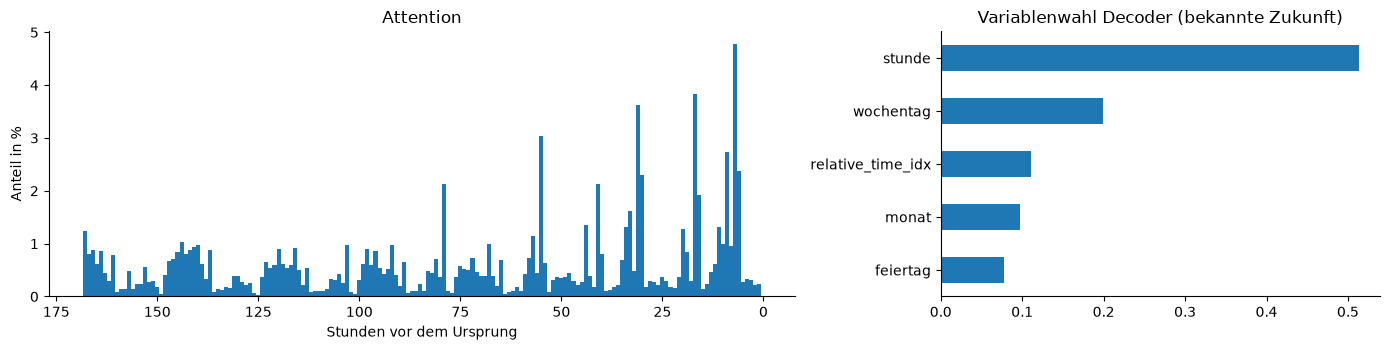

Attention-Anteil je Tag zurueck (1 = letzte 24 h): ['25%', '18%', '13%', '12%', '10%', '11%', '11%']


In [15]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 TFT nur LADEN und befragen (nicht trainieren): fuer jeden der 28 Ursprunge ein Fenster 168 h + 24 h an den TFT geben,
# 🎓 drei Quantile (10/50/90 %) und Deutungshilfen (Attention, Variablengewichte) einsammeln. Faellt bei Fehler auf
# 🎓 results_referenz/ zurueck (NUTZE_REFERENZ = True erzwingt das). Die vielen 'GPU available'-Zeilen in der Ausgabe ignorieren.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 5")
NUTZE_REFERENZ = False                     # True: mitgelieferte Vorhersagen laden (falls der TFT nicht laeuft)
try:
    if NUTZE_REFERENZ: raise RuntimeError("Referenz gewaehlt")
    import logging; logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
    from pytorch_forecasting import TemporalFusionTransformer
    tft = TemporalFusionTransformer.load_from_checkpoint(TFT_CKPT, map_location="cpu"); tft.eval()
    # 🎓 Daten genau so aufbereiten wie beim Training des TFT: Zeit + Last + Kalender als Spalten.
    d = df.reset_index()[["ds", "load_mw"]].copy()          # dieselbe Aufbereitung wie beim Training
    # 🎓 kalender() hat Zeitindex, d einen 0..N-Index -> reset_index(drop=True), damit concat zeilenweise passt.
    d = pd.concat([d, kalender(d.ds).reset_index(drop=True)], axis=1)
    # 🎓 pytorch-forecasting braucht eine laufende Ganzzahl-Zeit (time_idx) und eine Gruppen-ID (serie).
    d["time_idx"] = np.arange(len(d)); d["serie"] = "amprion"; d["load_mw"] = d["load_mw"].astype(float)
    # 🎓 Kalender als Text = kategoriale Variablen (so wurde der TFT trainiert – Embeddings statt Zahlen).
    for c in ["stunde", "wochentag", "monat", "feiertag"]: d[c] = d[c].astype(str)
    t0 = time.time(); Q, ATT, VI = [], [], []
    for o in URSPRUENGE:
        # 🎓 Zeilennummer des Ursprungs o (00:00 UTC des Prognosetags) in d.
        i0 = d.index[d.ds == o][0]
        # 🎓 SCHNITT: Zeilen i0-168 .. i0+23 (192 Zeilen)
        # 🎓   erste 168 Zeilen = Encoder: Vergangenheit bis 23:00 des Vortags, mit Last und Kalender
        # 🎓   letzte 24 Zeilen = Decoder: der Prognosetag, nur die BEKANNTEN Merkmale (Kalender) werden als Eingabe genutzt.
        # 🎓   Die Lastwerte dieser 24 Zeilen stehen zwar in d, sind fuer den TFT aber das Ziel, keine Eingabe.
        fen = d.iloc[i0 - 168:i0 + 24]                        # 168 h Vergangenheit + 24 h bekannte Zukunft (Kalender)
        # 🎓 accelerator="cpu": sonst nimmt Lightning auf Apple-Silicon-Macs MPS -> Kernel-Absturz (nicht abfangbar).
        roh = tft.predict(fen, mode="raw", return_x=True, trainer_kwargs=dict(accelerator="cpu", logger=False, enable_progress_bar=False))
        # 🎓 prediction[0] = erstes (einziges) Fenster, Form (24, 3) = 24 Stunden x 3 Quantile;
        # 🎓 fen.ds.iloc[168:] = die 24 Zeitstempel des Prognosetags als Index.
        Q.append(pd.DataFrame(roh.output.prediction[0].numpy(), columns=["q10", "q50", "q90"], index=fen.ds.iloc[168:]))
        deut = tft.interpret_output(roh.output, reduction="sum")
        ATT.append(deut["attention"].numpy()); VI.append(deut["decoder_variables"].numpy())
    p_tft = pd.concat(Q); print(f"Inferenz: {time.time() - t0:.1f} s")
    # 🎓 Mittel ueber die 28 Ursprunge, dann auf Summe 1 normiert -> Anteile. att[0] = aelteste Stunde (168 h vorher),
    # 🎓 att[167] = juengste Stunde (1 h vorher = 23:00 Vortag).
    att = np.mean(ATT, axis=0); att /= att.sum()
    vi = pd.Series(np.mean(VI, axis=0), index=tft.decoder_variables); vi /= vi.sum()
except Exception as e:
    print(f"TFT nicht nutzbar ({type(e).__name__}: {e}) -> Referenzvorhersagen aus results_referenz/")
    p_tft = pd.read_csv(REFDIR / "tft_backtest.csv", index_col=0, parse_dates=True)
    att = np.load(REFDIR / "tft_attention.npy"); vi = pd.Series(json.load(open(REFDIR / "tft_variablen.json")))
p_tft.index = pd.DatetimeIndex(p_tft.index); p_tft.index.name = "ds"
ERGEBNISSE.append(bewerte("TFT (Median)", p_tft["q50"])); print(ERGEBNISSE[-1])
check("5.1 TFT: Median-MAE 598 MW", lambda: nah(ERGEBNISSE[-1]["MAE"], 598, 5))

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
# 🎓 x = 168 - i: Position i -> 'Stunden vor dem Ursprung' (168 .. 1); invert_xaxis -> Ursprung rechts, Zeit laeuft nach rechts.
axs[0].bar(168 - np.arange(len(att)), att * 100, width=1); axs[0].invert_xaxis()
axs[0].set_xlabel("Stunden vor dem Ursprung"); axs[0].set_ylabel("Anteil in %"); axs[0].set_title("Attention")
vi.sort_values().plot.barh(ax=axs[1], title="Variablenwahl Decoder (bekannte Zukunft)"); plt.tight_layout(); plt.show()
# 🎓 SCHNITT je Tag zurueck: k = 0 -> att[144:168] = die letzten 24 h (gestern); k = 1 -> att[120:144] = vorgestern; ...
# 🎓   k = 6 -> att[0:24] = vor 7 Tagen. Summe je Block = Attention-Anteil dieses Tages.
# 🎓   Typisches Ergebnis: gestern ≈ 25 %, dann abfallend auf ≈ 10 %; Tag 6–7 (Vorwoche) halten sich bei ≈ 11 %.
tage = [att[(168 - 24 * (k + 1)):(168 - 24 * k)].sum() for k in range(7)]   # Anteil je Tag zurueck
print("Attention-Anteil je Tag zurueck (1 = letzte 24 h):", [f"{t:.0%}" for t in tage])

### 5.2 · Das Band prüfen

`CODE` (2 Zeilen) · Ein 10–90-%-Band sollte im Mittel **80 %** der Ist-Werte enthalten (*Abdeckung*). Berechnen Sie die Abdeckung
(Anteil der Stunden mit $q_{0,1} \le y \le q_{0,9}$) und den Pinball-Verlust je Quantil:

$$L_\tau(y, q) = \begin{cases} \tau\,(y - q) & y \ge q \\ (1 - \tau)\,(q - y) & y < q \end{cases} \qquad\text{in NumPy:}\quad
e = y - q,\ \ L = \max(\tau e,\ (\tau - 1) e)$$

**Erwartung:** Abdeckung 53 % · Pinball $q_{0,1}$ 195 · $q_{0,5}$ 299 · $q_{0,9}$ 123 MW.

Abdeckung des 10–90-%-Bands: 52.8% (Soll 80 %) | Pinball: {'q10': 195, 'q50': 299, 'q90': 123}
✅ 5.2 Abdeckung 53 %
✅ 5.2 Pinball q50 = halber MAE des Medians


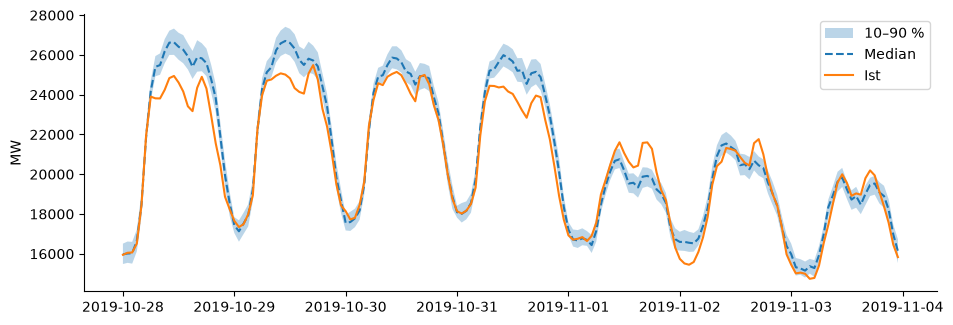

In [16]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Unsicherheitsband pruefen: Abdeckung (Soll 80 %, Ist ≈ 53 % -> Band deutlich zu schmal) und Pinball-Verlust je Quantil.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
ist = y.loc[p_tft.index]
# TODO 5.2a (Loesung): abdeckung = Anteil der Stunden mit q10 <= ist <= q90 (Mittelwert einer booleschen Series)
# 🎓 Zwei boolesche Series per & verknuepfen -> True, wenn ist im Band liegt; .mean() von True/False = Anteil.
abdeckung = float(((ist >= p_tft["q10"]) & (ist <= p_tft["q90"])).mean())
def pinball(ist, q, tau):
    e = ist - q
    # TODO 5.2b (Loesung): mittlerer Pinball-Verlust: np.mean(np.maximum(tau * e, (tau - 1) * e))
    # 🎓 np.maximum waehlt je Stunde den richtigen Fall: e >= 0 -> tau·e ist >= 0 und gewinnt; e < 0 -> (tau-1)·e > 0 gewinnt.
    return float(np.mean(np.maximum(tau * e, (tau - 1) * e)))
# 🎓 Schleife ueber tau = 0,1 / 0,5 / 0,9; f"q{int(t*100)}" baut den Spaltennamen q10 / q50 / q90.
pb = {f"q{int(t * 100)}": round(pinball(ist, p_tft[f"q{int(t * 100)}"], t)) for t in (0.1, 0.5, 0.9)}
print(f"Abdeckung des 10–90-%-Bands: {abdeckung:.1%} (Soll 80 %) | Pinball: {pb}")
check("5.2 Abdeckung 53 %", lambda: nah(abdeckung, 0.528, 0.01))
# 🎓 Probe: Pinball bei tau = 0,5 ist genau der halbe MAE (0,5·|e|) – schoene Bruecke zu 2.1.
check("5.2 Pinball q50 = halber MAE des Medians", lambda: nah(pinball(ist, p_tft["q50"], 0.5), mae(ist.values, p_tft["q50"].values) / 2, 1e-6))
# 🎓 Gleiche Woche wie in 3.3 (28.10.–3.11.): fill_between zeichnet das 10–90-%-Band, darueber Median und Ist.
w = slice("2019-10-28", "2019-11-03 23:00")
plt.fill_between(p_tft.loc[w].index, p_tft.loc[w, "q10"], p_tft.loc[w, "q90"], alpha=0.3, label="10–90 %")
plt.plot(p_tft.loc[w, "q50"], "--", label="Median"); plt.plot(y.loc[w], label="Ist"); plt.legend(); plt.ylabel("MW"); plt.show()
save_log("a5_tft", mae_median=ERGEBNISSE[-1]["MAE"], abdeckung=abdeckung, pinball=pb)

### 5.3 · Vergleich, Empfehlung, Endtest

`AUSFÜHREN` + `DENKEN` · Die Tabelle fasst alle Modelle im selben Backtest zusammen. Schreiben Sie darunter **drei Sätze**: Welches
Modell würden Sie dem Netzbetreiber empfehlen – und warum (Genauigkeit, Aufwand, Unsicherheit, Erklärbarkeit)? Erst **danach**
setzen Sie `ENDTEST_FREIGEBEN = True` und rechnen den Endtest (Dezember 2019) **genau einmal** für Ihr Modell.
**Erwartung Endtest:** LightGBM 838 MW · Netzbetreiber 821 MW · saisonal naiv 1 886 MW.

In [17]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Vergleichstabelle aller Modelle im selben Backtest, nach MAE sortiert.
# 🎓 drop_duplicates(keep='last'): wurden Zellen mehrfach ausgefuehrt, steht ein Modell mehrfach in ERGEBNISSE -> nur das letzte behalten.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
tab = pd.DataFrame(ERGEBNISSE).drop_duplicates("Modell", keep="last").set_index("Modell").sort_values("MAE")
display(tab)
save_log("a5_vergleich", tabelle=tab.reset_index().to_dict(orient="records"))

,MAE,RMSE,MAPE,MASE
Modell,,,,
Netzbetreiber (Day-ahead),466,574,2.29,0.438
LightGBM,488,616,2.40,0.459
TFT (Median),598,761,2.89,0.563
MSTL + ETS,673,987,3.26,0.633
LSTM,745,953,3.57,0.701
Saisonal naiv (Vorwoche),927,1467,4.43,0.872
Naiv (Vortag),1562,2350,7.64,1.469
"SARIMA(3,0,0)(2,1,0)24",1620,2132,7.78,1.523
"ETS(A,N,A), s = 24",1758,2255,8.65,1.654


**Meine Empfehlung (3 Sätze):**

*…*

*Beispiel-Lösung:* LightGBM ist mit 488 MW fast so genau wie der Netzbetreiber (466 MW) und trainiert in unter einer Sekunde ohne
GPU; der TFT ist ungenauer (598 MW) und aufwendiger, liefert aber ein Unsicherheitsband, das allerdings zu schmal ist (53 % statt 80 %).
Empfehlung: LightGBM als Arbeitsmodell, saisonal naiv als ständige Baseline im Monitoring, Unsicherheit über Quantil-LightGBM
nachrüsten. Der größte Hebel ist ein zusätzliches Merkmal: die Temperatur.

In [18]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Endtest Dezember 2019 – GENAU EINMAL, erst nach der Empfehlung. In der Loesung ist der Schalter schon auf True gesetzt
# 🎓 (zweite Zeile). In der Vorfuehrung: erst die Empfehlung diskutieren, dann ausfuehren.
# 🎓 LightGBM wird NICHT neu trainiert (Stand 30.9.2019); X.loc[ENDTEST] enthaelt nur Lags >= 24 h -> gueltige Day-ahead-Prognosen.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
ENDTEST_FREIGEBEN = False                  # erst nach der Empfehlung auf True setzen – und nur einmal ausfuehren
ENDTEST_FREIGEBEN = True
if ENDTEST_FREIGEBEN:
    endtest = [bewerte("LightGBM", pd.Series(gbm.predict(X.loc[ENDTEST]), index=ENDTEST)),
               bewerte("Saisonal naiv", y.shift(168).loc[ENDTEST]),
               bewerte("Netzbetreiber", df["load_forecast_tso_mw"].astype(float).loc[ENDTEST])]
    display(pd.DataFrame(endtest).set_index("Modell"))
    check("5.3 Endtest Dezember: LightGBM 838 MW", lambda: nah(endtest[0]["MAE"], 838, 5))
    save_log("a5_endtest", ergebnisse=endtest)

,MAE,RMSE,MAPE,MASE
Modell,,,,
LightGBM,838,1105,4.11,0.789
Saisonal naiv,1886,2597,9.87,1.774
Netzbetreiber,821,1056,3.93,0.772


✅ 5.3 Endtest Dezember: LightGBM 838 MW


**`DENKEN`:** a) Warum ist das Band zu schmal? b) Warum darf der Endtest nur einmal gerechnet werden? c) Warum ist der Endtest-MAE
fast doppelt so hoch wie im Backtest?

*Lösung:* a) Feiertage und Ausnahmetage sind im Training selten; die Quantile sind auf „normale“ Tage kalibriert. b) Wer nach dem
Endtest das Modell wechselt, wählt auf dem Test aus – er wird zum Validierungsset und die Zahl zu optimistisch. c) Der Dezember
ist schwerer (Vorweihnachtszeit, Weihnachtswoche, Brückentage) – der Backtest-MAE ist eine Schätzung, kein Versprechen.

## Aufgabe 6 · Drift und Anomalien

**Block nach „Zwischenstand: Anomalien und Drift“ · 10 Min.** · Folien Abschnitt 5 · FPP3 5.4 · Liu et al. (2008)

### 6.1 · Das Modell durch den Lockdown schicken

`CODE` (2 Zeilen) · Das LightGBM aus Aufgabe 4 bleibt **unverändert** (Stand 30.9.2019) und sagt vom 1.10.2019 bis 30.6.2020 voraus.
Berechnen Sie das Residuum $e_t = y_t - \hat y_t$ und je Monat den **MAE** (Mittel von $|e|$) und den **Bias** (Mittel von $e$).
Hilfe: `reihe.resample("MS").mean()` bildet Monatsmittel.
**Erwartung Bias:** Jan −306 · Mär −350 · Apr −302 · Mai −321 MW · MAE Apr 613 MW (Netzbetreiber 1 075 MW).

,MAE,Bias,MAE_TSO
2019-10-01,492.0,-63.0,466.0
2019-11-01,653.0,69.0,459.0
2019-12-01,878.0,-136.0,986.0
2020-01-01,684.0,-306.0,719.0
2020-02-01,616.0,-31.0,584.0
2020-03-01,699.0,-350.0,889.0
2020-04-01,613.0,-302.0,1075.0
2020-05-01,677.0,-321.0,1206.0
2020-06-01,584.0,-271.0,906.0


✅ 6.1 Bias April 2020 ≈ −302 MW, MAE April ≈ 613 MW


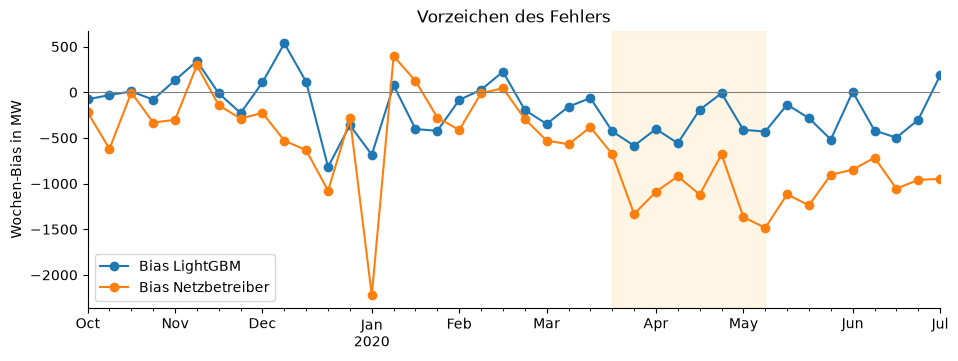

In [19]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Drift: das unveraenderte LightGBM von Okt. 2019 bis Juni 2020 laufen lassen (274 Tage, durch den Corona-Lockdown).
# 🎓 Residuum e = Ist - Prognose; je Monat MAE (Betrag) und Bias (Vorzeichen). Kernaussage: Drift sieht man am Bias, nicht am MAE.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Aufgabe 6")
DRIFT = pd.date_range("2019-10-01", "2020-06-30 23:00", freq="h")
# 🎓 Series minus NumPy-Array -> Series mit Zeitindex DRIFT. Negativ = Modell schaetzt zu hoch.
res = y.loc[DRIFT] - gbm.predict(X.loc[DRIFT])                         # Residuum LightGBM
res_tso = y.loc[DRIFT] - df["load_forecast_tso_mw"].loc[DRIFT]           # Residuum Netzbetreiber
# TODO 6.1 (Loesung): monat = DataFrame mit Spalten MAE (res.abs() Monatsmittel), Bias (res Monatsmittel), MAE_TSO
# 🎓 resample('MS') = Monatsmittel, beschriftet mit dem Monatsersten -> Zugriff z. B. monat.loc['2020-04-01'].
monat = pd.DataFrame({"MAE": res.abs().resample("MS").mean(), "Bias": res.resample("MS").mean(),
                      "MAE_TSO": res_tso.abs().resample("MS").mean()}).round(0)
display(monat)
check("6.1 Bias April 2020 ≈ −302 MW, MAE April ≈ 613 MW",
      lambda: nah(monat.loc["2020-04-01", "Bias"], -302, 5) and nah(monat.loc["2020-04-01", "MAE"], 613, 5))
# 🎓 resample('W-SUN') = Wochen von Mo bis So, beschriftet mit dem Sonntag. Orange Flaeche = Lockdown 16.3.–10.5.2020.
woche = pd.DataFrame({"Bias LightGBM": res.resample("W-SUN").mean(), "Bias Netzbetreiber": res_tso.resample("W-SUN").mean()})
ax = woche.plot(marker="o", ylabel="Wochen-Bias in MW", title="Vorzeichen des Fehlers")
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-05-10"), alpha=0.1, color="orange"); ax.axhline(0, color="grey", lw=0.8); plt.show()
save_log("a6_drift", monat=monat.reset_index(names="monat").astype({"monat": str}).to_dict(orient="records"))

### 6.2 · Isolation Forest auf Tagesmerkmalen

`CODE` (2 Zeilen) · Je Tag drei Merkmale des Residuums: Mittelwert, Standardabweichung, größter Betrag. Ein Isolation Forest
(`IsolationForest(n_estimators=200, contamination=0.05, random_state=0)`) markiert die 5 % auffälligsten Tage. `fit(F)`,
dann `predict(F)` (−1 = Anomalie) und `score_samples(F)` (je kleiner, desto auffälliger).
**Erwartung:** 14 von 274 Tagen; die fünf mit höchstem Score: 24.12.2019, 1.1.2020, 1.12.2019, 24.2.2020, 3.12.2019.

,mittel,streuung,max_abs,anomalie,score
2019-12-24,-2839.0,1428.0,5783.0,True,1.0
2020-01-01,-2464.0,1406.0,5467.0,True,1.0
2019-12-01,1117.0,1223.0,4900.0,True,1.0
2020-02-24,-1785.0,1239.0,3787.0,True,1.0
2019-12-03,1560.0,991.0,3312.0,True,1.0
2019-12-31,-1966.0,929.0,3291.0,True,1.0
2020-01-06,81.0,1389.0,2483.0,True,1.0
2019-12-02,858.0,1208.0,2978.0,True,1.0
2020-05-21,-1382.0,716.0,2774.0,True,1.0
2019-11-19,3.0,1223.0,1895.0,True,1.0


✅ 6.2 14 Anomalien, auffaelligster Tag 24.12.2019


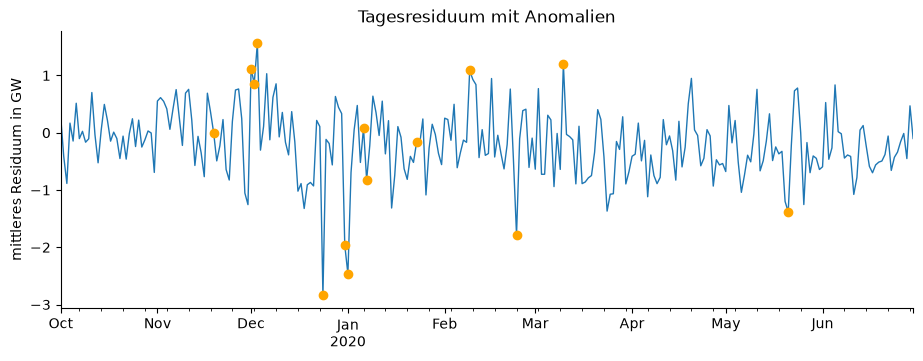

In [20]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Isolation Forest auf Tagesebene: je Tag drei Kennzahlen des Residuums -> 274 Zeilen -> die 5 % auffaelligsten Tage markieren.
# 🎓 Achtung: F und tag werden hier neu belegt (vorher LSTM-Merkmalsmatrix bzw. Tagesmittel aus 1.2) – fuer A6 egal.
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
tag = res.resample("D")
# 🎓 mittel = Bias des Tages, streuung = Std. der 24 Residuen, max_abs = groesster Einzelfehler des Tages.
F = pd.DataFrame({"mittel": tag.mean(), "streuung": tag.std(), "max_abs": tag.apply(lambda s: s.abs().max())})
# TODO 6.2 (Loesung): iso anlegen und fitten; F["anomalie"] = (iso.predict(...) == -1); F["score"] = -iso.score_samples(...)
# 🎓 contamination = 0,05 -> Schwelle so, dass ≈ 5 % der Tage Anomalien sind: 0,05 x 274 ≈ 14 Tage.
iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=0).fit(F[["mittel", "streuung", "max_abs"]])
# 🎓 predict: -1 = Anomalie, +1 = normal -> == -1 macht daraus True/False.
F["anomalie"] = iso.predict(F[["mittel", "streuung", "max_abs"]]) == -1
# 🎓 score_samples: je KLEINER, desto auffaelliger -> Vorzeichen umdrehen, damit 'groesser = auffaelliger'.
F["score"] = -iso.score_samples(F[["mittel", "streuung", "max_abs"]])     # groesser = auffaelliger
top = F[F.anomalie].sort_values("score", ascending=False)
display(top.round(0).head(14))
check("6.2 14 Anomalien, auffaelligster Tag 24.12.2019",
      lambda: int(F.anomalie.sum()) == 14 and top.index[0] == pd.Timestamp("2019-12-24"))
ax = (F["mittel"] / 1000).plot(lw=1, ylabel="mittleres Residuum in GW", title="Tagesresiduum mit Anomalien")
# 🎓 Orange Punkte = markierte Tage: Feiertage/Brueckentage; der Lockdown selbst faellt kaum auf (Drift ≠ Ausnahme).
ax.scatter(top.index, top["mittel"] / 1000, color="orange", zorder=3); plt.show()
save_log("a6_anomalien", tage=[str(t.date()) for t in top.index], anzahl=int(F.anomalie.sum()))

**`DENKEN` – Interpretation**

a) LightGBM bleibt im Lockdown beim MAE stabil, der Netzbetreiber nicht – warum? b) Warum findet der Isolation Forest den Lockdown
kaum, Heiligabend aber sofort? c) Welche zwei Merkmale würden Sie als Nächstes ergänzen?

*Lösung:* a) Die Lags (Vortag, Vorwoche) enthalten das neue Niveau – das Modell zieht nach 24 h nach; übrig bleibt ein Bias von
≈ −300 MW (Lag 168/336 erinnern an den „alten“ Montag). Drift erkennt man deshalb am Bias, nicht am MAE allein. b) Der Isolation
Forest vergleicht Tage untereinander; viele Lockdown-Tage ähneln sich – Drift ist eine Verschiebung, keine Ausnahme. Heiligabend
ist ein Einzelfall. c) Heiligabend/Silvester/Brückentage (Kalender) und die Temperatur.

## Laufzeiten und Prüfungen

`AUSFÜHREN` · Reine Rechenzeit je Aufgabe und Übersicht aller Prüfungen.

In [21]:
# 🎓 DOZENT ─────────────────────────────────────────────────────────────────────────────────────────
# 🎓 Abschluss: Rechenzeit je Aufgabe und Liste aller Pruefungen. In der Vorfuehrung nur kurz zeigen: alles ✅?
# 🎓 ──────────────────────────────────────────────────────────────────────────────────────────────
abschnitt("Abschluss")
display(pd.DataFrame({"Rechenzeit (s)": RUNTIME}).round(1))
pflicht = sum(v for k, v in RUNTIME.items() if k.startswith("Aufgabe"))
print(f"Pflichtteil (Aufgaben 0-6): {pflicht / 60:.1f} Min. | Threads: {torch.get_num_threads()}")
save_log("laufzeiten", runtime_s=RUNTIME, pflicht_min=pflicht / 60, cpu_kerne=os.cpu_count())
print(f"Pruefungen: {sum(CHECKS.values())} ✅ / {sum(not v for v in CHECKS.values())} ❌")
for name, ok in CHECKS.items():
    if not ok:
        print("  ❌", name)

,Rechenzeit (s)
Aufgabe 1,0.7
Aufgabe 2,0.1
Aufgabe 3,22.4
Aufgabe 4,11.6
Aufgabe 5,2.5
Aufgabe 6,0.3


Pflichtteil (Aufgaben 0-6): 0.6 Min. | Threads: 4
Pruefungen: 23 ✅ / 0 ❌
